# RoadGuard — Approved Pipeline (Members 1–5)

Member 1 and Member 5 cells are retained verbatim from RoadGuard (6).ipynb. Members 2–4 follow the original notebook structure, naming conventions and comments. Only Development predictions and metrics are generated by the updated sections. **Do not use Run All**: Member 5 retains its original Test code for its owner to run later.


## Member 1 — Original dataset preparation (unchanged)


In [ ]:
# Import required libraries, connect Google Drive, and define the dataset path.
import os
import zipfile
import numpy as np
import pandas as pd

from google.colab import drive
from sklearn.model_selection import train_test_split

# drive.mount('/content/drive')
drive.mount('/content/drive', force_remount=True)

dataset_zip = '/content/drive/MyDrive/RoadGuard_Project/Dataset/RDD2022.zip'

assert os.path.exists(dataset_zip), "Dataset not found"

# Read file paths from the ZIP archive.
with zipfile.ZipFile(dataset_zip, 'r') as z:
    files = z.namelist()

image_extensions = ('.jpg', '.jpeg', '.png', '.bmp')


Mounted at /content/drive


In [ ]:
# Extract image and label paths from the ZIP archive.

image_paths = [
    f for f in files
    if f.lower().endswith(image_extensions)
]

label_paths = [
    f for f in files
    if f.lower().endswith('.txt')
]

image_ids = [
    os.path.splitext(os.path.basename(f))[0]
    for f in image_paths
]

label_ids = [
    os.path.splitext(os.path.basename(f))[0]
    for f in label_paths
]

# Check for duplicate file names.
assert len(image_ids) == len(set(image_ids)), "Duplicate image names found"

assert len(label_ids) == len(set(label_ids)), "Duplicate label names found"

images = dict(zip(image_ids, image_paths))
labels = dict(zip(label_ids, label_paths))

# Verify image-label matching.
assert images.keys() == labels.keys(), "Image-label mismatch"

print("Images:", len(images))
print("Labels:", len(labels))


Images: 38385
Labels: 38385


In [ ]:
# Validate annotation files and create a dataset containing valid image-label pairs.
records = []

with zipfile.ZipFile(dataset_zip, 'r') as z:
    for name, image_path in images.items():
        label_path = labels[name]
        content = z.read(label_path).decode('utf-8').strip()

        boxes = []
        valid = True

        if content:
            for line in content.splitlines():
                values = line.split()

                if len(values) != 5:
                    valid = False
                    break

                try:
                    class_id = int(values[0])
                    box = np.array(values[1:], dtype=float)

                    if class_id not in range(5):
                        valid = False
                        break

                    if not np.all(np.isfinite(box)):
                        valid = False
                        break

                    if np.any(box < 0) or np.any(box > 1):
                        valid = False
                        break

                    if box[2] <= 0 or box[3] <= 0:
                        valid = False
                        break

                    boxes.append([class_id, *box.tolist()])

                except ValueError:
                    valid = False
                    break

        if valid:
            records.append({
                "image_path": image_path,
                "label_path": label_path,
                "boxes": boxes
            })

clean_df = pd.DataFrame(records).reset_index(drop=True)

print("Valid images:", len(clean_df))


Valid images: 38384


In [ ]:
# Select 6,000 valid images, split them into Development and Test sets, and verify the dataset sizes and ensure there is no overlap.
assert len(clean_df) >= 6000

sample_df = clean_df.sample(
    n=6000,
    random_state=42
).reset_index(drop=True)

trainval_df, test_df = train_test_split(
    sample_df,
    test_size=900,
    random_state=42,
    shuffle=True
)

train_df, val_df = train_test_split(
    trainval_df,
    test_size=900,
    random_state=42,
    shuffle=True
)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))
print("Total:", len(train_df) + len(val_df) + len(test_df))

assert set(train_df.image_path).isdisjoint(val_df.image_path)
assert set(train_df.image_path).isdisjoint(test_df.image_path)
assert set(val_df.image_path).isdisjoint(test_df.image_path)

assert len(train_df) == 4200
assert len(val_df) == 900
assert len(test_df) == 900


Training: 4200
Validation: 900
Testing: 900
Total: 6000


In [ ]:
# Combine Training and Validation sets into the Development Set.
development_df = pd.concat(
    [train_df, val_df],
    ignore_index=True
)

print("Development Set:", len(development_df))
print("Test Set:", len(test_df))

assert len(development_df) == 5100
assert len(test_df) == 900


Development Set: 5100
Test Set: 900


In [ ]:
# Resize images while preserving aspect ratio and record image dimensions.
import cv2
MAX_SIZE = 512

def resize_image(image_bytes):
    image = cv2.imdecode(
        np.frombuffer(image_bytes, np.uint8),
        cv2.IMREAD_COLOR
    )

    if image is None:
        raise ValueError("Unable to read image")

    original_h, original_w = image.shape[:2]

    scale = min(
        1.0,
        MAX_SIZE / max(original_h, original_w)
    )

    new_w = round(original_w * scale)
    new_h = round(original_h * scale)

    resized = cv2.resize(
        image,
        (new_w, new_h),
        interpolation=cv2.INTER_AREA
    )

    metadata = {
         "original_width": original_w,
         "original_height": original_h,
         "resized_width": new_w,
         "resized_height": new_h,
         "scale_factor": scale,
         "scale_x": new_w / original_w,
         "scale_y": new_h / original_h
    }

    return resized, metadata


In [ ]:
# Convert the resized image to Grayscale.
def convert_to_grayscale(resized_image):

    gray_image = cv2.cvtColor(
        resized_image,
        cv2.COLOR_BGR2GRAY
    )

    return gray_image


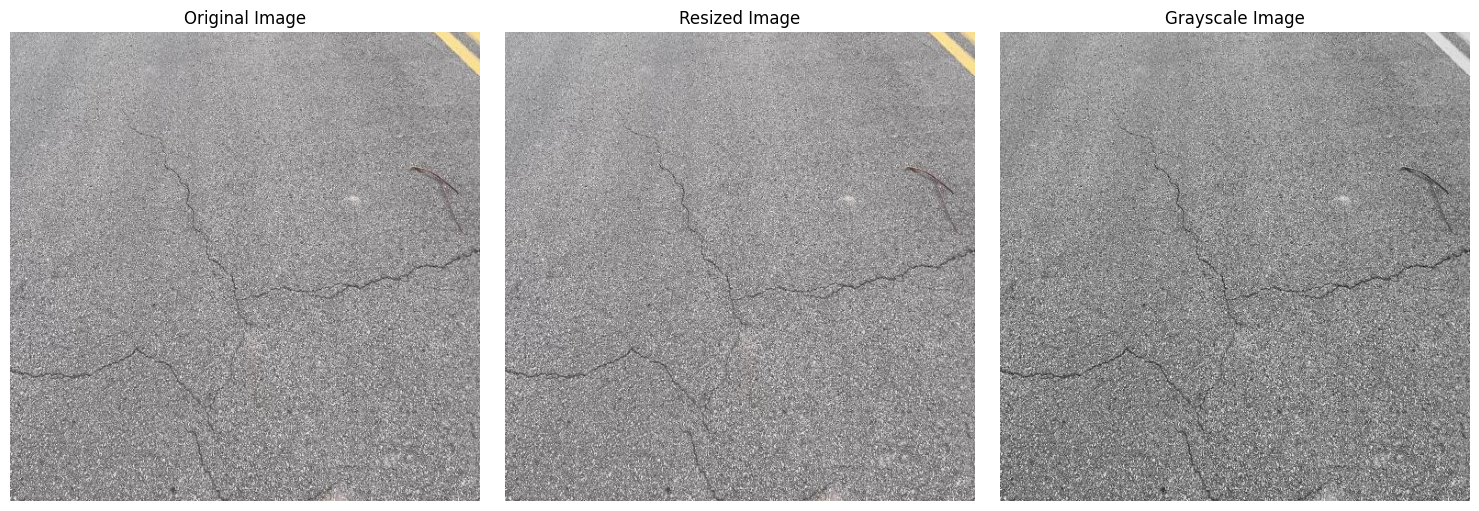

Original dimensions: 512 x 512
Resized dimensions: 512 x 512
Scale factor: 1.0


In [ ]:
# Display an image before and after Resize and Grayscale transformations.
import matplotlib.pyplot as plt

sample = train_df.iloc[5]

with zipfile.ZipFile(dataset_zip, 'r') as z:
    image_bytes = z.read(sample["image_path"])

resized_image, metadata = resize_image(image_bytes)
gray_image = convert_to_grayscale(resized_image)

original_image = cv2.imdecode(
    np.frombuffer(image_bytes, np.uint8),
    cv2.IMREAD_COLOR
)
original_image = cv2.cvtColor(original_image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cv2.cvtColor(resized_image, cv2.COLOR_BGR2RGB))
plt.title("Resized Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(gray_image, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Original dimensions:",
      metadata["original_width"], "x", metadata["original_height"])

print("Resized dimensions:",
      metadata["resized_width"], "x", metadata["resized_height"])

print("Scale factor:", metadata["scale_factor"])


In [ ]:
# Resize and convert all Development and Test images to Grayscale, save the processed images and labels, and record image metadata.
from pathlib import Path
from tqdm.auto import tqdm

output_dir = "/content/drive/MyDrive/RoadGuard_Project/Dataset/Processed"

folders = {
    "Development": os.path.join(output_dir, "Development"),
    "Test": os.path.join(output_dir, "Test")
}

for folder in folders.values():
    os.makedirs(os.path.join(folder, "Grayscale"), exist_ok=True)
    os.makedirs(os.path.join(folder, "Labels"), exist_ok=True)

all_df = pd.concat(
    [development_df, test_df],
    ignore_index=True
)

image_ids = [
    os.path.splitext(os.path.basename(path))[0]
    for path in all_df["image_path"]
]

assert len(image_ids) == len(set(image_ids)), "Duplicate image names found"

metadata_records = []

def process_dataset(df, split_name, z):

    for row in tqdm(df.itertuples(index=False), total=len(df), desc=split_name):

        image_id = Path(row.image_path).stem

        image_bytes = z.read(row.image_path)
        label_bytes = z.read(row.label_path)

        resized_image, metadata = resize_image(image_bytes)
        gray_image = convert_to_grayscale(resized_image)

        gray_path = os.path.join(
            folders[split_name],
            "Grayscale",
            image_id + ".png"
        )

        success = cv2.imwrite(gray_path, gray_image)
        assert success, f"Failed to save {image_id}"

        label_path = os.path.join(
            folders[split_name],
            "Labels",
            image_id + ".txt"
        )

        with open(label_path, "wb") as f:
            f.write(label_bytes)

        metadata_records.append({
            "image_id": image_id,
            "dataset_split": split_name,
            "original_image_path": row.image_path,
            "original_label_path": row.label_path,
            "processed_image_path": gray_path,
            "saved_label_path": label_path,
            **metadata
        })


with zipfile.ZipFile(dataset_zip, 'r') as z:

    process_dataset(development_df, "Development", z)
    process_dataset(test_df, "Test", z)


metadata_df = pd.DataFrame(metadata_records)

metadata_path = os.path.join(output_dir, "Metadata.csv")
metadata_df.to_csv(metadata_path, index=False)

print("Development images processed:", len(development_df))
print("Test images processed:", len(test_df))
print("Total processed images:", len(metadata_df))


Development:   0%|          | 0/5100 [00:00<?, ?it/s]

KeyboardInterrupt: 

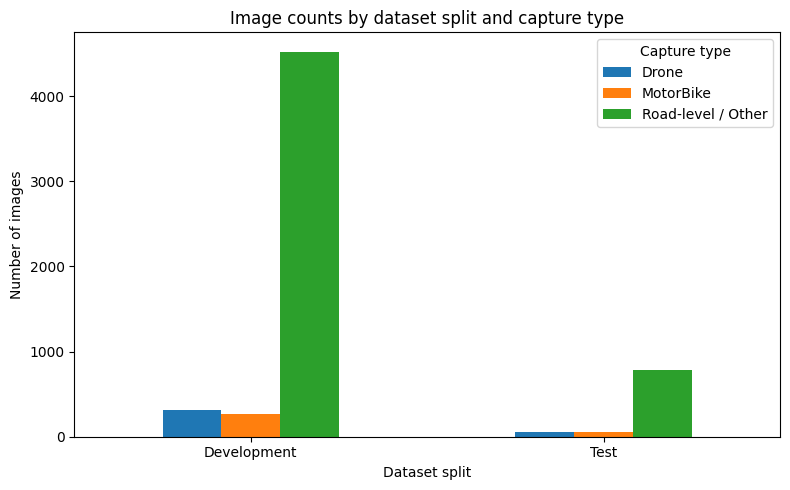

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

M1_IMAGE_COUNTS = []

for split in ["Development", "Test"]:
    image_dir = PROCESSED / split / "Grayscale"

    for image_path in image_dir.glob("*.png"):
        name = image_path.stem.lower()

        if "drone" in name:
            image_type = "Drone"
        elif "motorbike" in name:
            image_type = "MotorBike"
        else:
            image_type = "Road-level / Other"

        M1_IMAGE_COUNTS.append({
            "split": split,
            "image_type": image_type
        })

M1_IMAGE_COUNTS = pd.DataFrame(M1_IMAGE_COUNTS)
M1_IMAGE_COUNTS = (
    M1_IMAGE_COUNTS
    .groupby(["split", "image_type"])
    .size()
    .unstack(fill_value=0)
)

ax = M1_IMAGE_COUNTS.plot(
    kind="bar",
    figsize=(8, 5)
)

ax.set_title("Image counts by dataset split and capture type")
ax.set_xlabel("Dataset split")
ax.set_ylabel("Number of images")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Capture type")
plt.tight_layout()
plt.show()

In [ ]:
# Verify that all processed images, labels, and metadata were saved successfully
development_images = os.listdir(
    os.path.join(folders["Development"], "Grayscale")
)

test_images = os.listdir(
    os.path.join(folders["Test"], "Grayscale")
)

development_labels = os.listdir(
    os.path.join(folders["Development"], "Labels")
)

test_labels = os.listdir(
    os.path.join(folders["Test"], "Labels")
)

assert len(development_images) == 5100
assert len(test_images) == 900

assert len(development_labels) == 5100
assert len(test_labels) == 900

assert len(metadata_df) == 6000
assert metadata_df.notnull().all().all()

assert os.path.exists(metadata_path)

print("Development images:", len(development_images))
print("Development labels:", len(development_labels))
print("Test images:", len(test_images))
print("Test labels:", len(test_labels))
print("Metadata records:", len(metadata_df))


AssertionError: 

In [ ]:
#END OF ZAINAB CODE

## Member 2 — Tuned Canny Baseline

Use Claude’s fixed configuration selected from 600 candidate configurations. No new tuning or Test evaluation. The shared processing functions below implement connected components, box merging and coordinate conversion.

Output folders under Dataset/Processed: `RoadGuard_Canny_Baseline_improved`, `Member3_Figures_improved`, and `Member4_Improved_Results_improved`. Each run uses a timestamped subfolder to avoid overwriting earlier experiments. Enhanced Development images are saved separately in `Development/Enhanced-IMAGE`.


In [1]:
import os, json, time, hashlib
from pathlib import Path
from datetime import datetime
import cv2, numpy as np, pandas as pd
from scipy.sparse.csgraph import connected_components
from tqdm.auto import tqdm
from IPython.display import display
# Same Drive access style as RoadGuard (5).ipynb: mount and use a fixed MyDrive path.
from google.colab import drive
drive.mount('/content/drive')

# Existing processed images and configurations are read from the original project.
ROOT = Path('/content/drive/MyDrive/RoadGuard_Project/Dataset')
PROCESSED = ROOT / 'Processed'
if not PROCESSED.is_dir():
    raise FileNotFoundError(
        f'Missing {PROCESSED}. Check the folder location in MyDrive. '
        'A Google Drive sharing URL is not a local Colab path.'
    )
print('Resolved dataset root:', ROOT)
PROCESSED = ROOT/'Processed'
for split in ('Development',):
 for folder in ('Grayscale','Enhanced'):
  assert (PROCESSED/split/folder).is_dir(), f'Missing: {PROCESSED/split/folder}'
assert (PROCESSED/'Development'/'Labels').is_dir()
M4_CONFIG_PATH = PROCESSED/'RoadGuard_Member4_Masks_iou50_v4'/'member4_selected_config_iou50_v4.json'
assert M4_CONFIG_PATH.exists(), f'Missing Member 4 config: {M4_CONFIG_PATH}'
BEST_CONFIG=json.loads(M4_CONFIG_PATH.read_text())
# Claude's winning configuration from the 600-setting search, provided by the user.
# Box scale kept at the original winning value 1.0.
# This is a fixed configuration: NO search and NO baseline config file required.
M2_FINAL_CONFIG = {
    'low': 50, 'high': 150, 'blur': 3,
    'roi_top_fraction': 0.6, 'min_component_pixels': 40,
    'merge_gap': 12, 'min_group_pixels': 600,
    'max_bbox_area_fraction': 0.8, 'min_box_area_fraction': 0.0,
    'max_boxes': 3, 'box_scale': 1.0,
    'rank': 'area', 'auto_sigma': None,
}
print('Using fixed tuned Canny configuration (box_scale=1.0):', M2_FINAL_CONFIG)
# Save beside the existing Member 4 results, in a clearly separate improved folder.
# Do not write to the existing Member4_Improved_Results folder.
RUN_ID='Approved_Improved_'+datetime.now().strftime('%Y%m%d_%H%M%S')
OUT=PROCESSED/'Member4_Improved_Results_improved'
OUT.mkdir(parents=True,exist_ok=True)
RUN_OUT=OUT/RUN_ID
RUN_OUT.mkdir(parents=True,exist_ok=False)
OUT=RUN_OUT
(OUT/'RUN_ID.txt').write_text(RUN_ID)
print('Member 4 improved experiment outputs:',OUT)
print('Existing folders are preserved.')


Mounted at /content/drive
Resolved dataset root: /content/drive/MyDrive/RoadGuard_Project/Dataset
Using fixed tuned Canny configuration (box_scale=1.0): {'low': 50, 'high': 150, 'blur': 3, 'roi_top_fraction': 0.6, 'min_component_pixels': 40, 'merge_gap': 12, 'min_group_pixels': 600, 'max_bbox_area_fraction': 0.8, 'min_box_area_fraction': 0.0, 'max_boxes': 3, 'box_scale': 1.0, 'rank': 'area', 'auto_sigma': None}
Member 4 improved experiment outputs: /content/drive/MyDrive/RoadGuard_Project/Dataset/Processed/Member4_Improved_Results_improved/Approved_Improved_20261123_134522
Existing folders are preserved.


In [2]:
# Member 2 - Read grayscale images and identify drone images.
def read_gray_image(image_path):
    """Read an already-preprocessed, one-channel uint8 image (Member 1 output)."""
    gray = cv2.imread(str(image_path), cv2.IMREAD_UNCHANGED)
    if gray is None:
        raise ValueError(f'Cannot read image: {image_path}')
    if gray.ndim != 2 or gray.dtype != np.uint8:
        raise ValueError(f'Expected an 8-bit grayscale image: {image_path}')
    return gray

def is_drone_image(image_stem):
    """Drone images are taken from above, so road can appear anywhere in the image."""
    return 'drone' in str(image_stem).lower()

In [3]:
# Member 2 - Apply Gaussian smoothing and tuned Canny edge detection.
def auto_canny_thresholds(gray, sigma):
    """Median-based thresholds: low / high = (1 -/+ sigma) x median intensity."""
    median = float(np.median(gray))
    low = int(max(0, (1.0 - sigma) * median))
    high = int(min(255, (1.0 + sigma) * median))
    return low, max(high, low + 1)

def canny_edges(gray, low_threshold=50, high_threshold=150, *, blur_kernel=0,
                auto_sigma=None, roi_top_fraction=0.0, image_stem=''):
    """Binary Canny edge map (0 / 255).

    blur_kernel      : 0 = none, odd size = Gaussian smoothing (Canny's own first step).
    auto_sigma       : None = fixed thresholds, a number = median-based thresholds per image.
    roi_top_fraction : drop edges in the top part of non-drone images (0 = full image).
    """
    if gray.ndim != 2 or gray.dtype != np.uint8:
        raise ValueError('Canny expects a 2-D uint8 grayscale image.')
    image = gray
    if blur_kernel:
        if blur_kernel < 3 or blur_kernel % 2 == 0:
            raise ValueError('blur_kernel must be 0 or an odd number >= 3.')
        image = cv2.GaussianBlur(gray, (blur_kernel, blur_kernel), 0)
    if auto_sigma is not None:
        low_threshold, high_threshold = auto_canny_thresholds(image, auto_sigma)
    if not 0 <= low_threshold < high_threshold:
        raise ValueError('Expected 0 <= low_threshold < high_threshold.')

    edges = cv2.Canny(image, low_threshold, high_threshold, apertureSize=3, L2gradient=True)
    if roi_top_fraction > 0 and not is_drone_image(image_stem):
        edges[:int(edges.shape[0] * roi_top_fraction), :] = 0
    return edges

In [4]:
# Member 2 - Extract connected components and candidate bounding boxes.
def extract_damage_boxes(binary_image, min_component_pixels=20,
                         min_bbox_side=2, max_bbox_area_fraction=0.80,
                         max_aspect_ratio=100.0, return_pixels=False):
    """Connected components (8-connectivity) -> boxes [x1, y1, x2, y2] (x2, y2 exclusive).

    Shared box function: the signature used elsewhere in the notebook is unchanged.
    return_pixels=True also returns the number of edge pixels in each box.
    """
    binary_image = np.asarray(binary_image)
    if binary_image.ndim != 2 or binary_image.size == 0:
        raise ValueError('Expected a non-empty 2-D binary image.')
    if not np.isin(binary_image, [0, 1, 255]).all():
        raise ValueError('Use a binary mask with values 0/1 or 0/255, not grayscale.')
    if min_component_pixels < 1 or min_bbox_side < 1:
        raise ValueError('Minimum component size and box side must be positive.')
    if not 0 < max_bbox_area_fraction <= 1 or not max_aspect_ratio >= 1:
        raise ValueError('Invalid maximum box area fraction or aspect ratio.')

    foreground = np.ascontiguousarray((binary_image > 0).astype(np.uint8))
    count, _, stats, _ = cv2.connectedComponentsWithStats(foreground, connectivity=8)
    image_h, image_w = foreground.shape
    boxes, pixels = [], []

    for component_id in range(1, count):  # component 0 is the background
        x, y, width, height, pixel_count = map(int, stats[component_id])
        if pixel_count < min_component_pixels:
            continue
        if min(width, height) < min_bbox_side:
            continue
        if (width * height) / (image_w * image_h) > max_bbox_area_fraction:
            continue
        if max(width / height, height / width) > max_aspect_ratio:
            continue
        boxes.append([x, y, x + width, y + height])
        pixels.append(pixel_count)

    return (boxes, pixels) if return_pixels else boxes
# Shared extraction function used by Member 2 and the improved pipeline.
_m2_extract_damage_boxes = extract_damage_boxes


In [5]:
# Member 2 - Merge nearby boxes and expand boxes when required.
def merge_nearby_boxes(boxes, pixels, gap):
    """Group boxes that overlap or are closer than `gap` pixels into one box.

    Canny breaks one crack into many short edge pieces; grouping their boxes gives one box per
    damaged area. Only box coordinates are used (no morphology on the image).
    """
    b = np.asarray(boxes, dtype=float).reshape(-1, 4)
    p = np.asarray(pixels, dtype=float)
    while len(b) > 1:
        dx = np.maximum(0, np.maximum(b[:, None, 0], b[None, :, 0]) - np.minimum(b[:, None, 2], b[None, :, 2]))
        dy = np.maximum(0, np.maximum(b[:, None, 1], b[None, :, 1]) - np.minimum(b[:, None, 3], b[None, :, 3]))
        n_groups, group = connected_components((dx <= gap) & (dy <= gap), directed=False)
        if n_groups == len(b):
            break  # nothing left to group
        merged = np.zeros((n_groups, 4))
        merged[:, :2] = np.inf
        np.minimum.at(merged[:, 0], group, b[:, 0])
        np.minimum.at(merged[:, 1], group, b[:, 1])
        np.maximum.at(merged[:, 2], group, b[:, 2])
        np.maximum.at(merged[:, 3], group, b[:, 3])
        b, p = merged, np.bincount(group, weights=p, minlength=n_groups)
    return b.astype(int).tolist(), p.astype(int).tolist()

def expand_box(box, image_shape, scale):
    """Scale a box around its centre (1.1 = 10% larger), clipped to the image."""
    height, width = image_shape
    x1, y1, x2, y2 = box
    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    new_w, new_h = max(1.0, (x2 - x1) * scale), max(1.0, (y2 - y1) * scale)
    return [max(0.0, cx - new_w / 2), max(0.0, cy - new_h / 2),
            min(float(width), cx + new_w / 2), min(float(height), cy + new_h / 2)]

In [6]:
# Member 2 - Complete tuned Canny baseline using the selected 600-search settings.
def baseline_predict(gray, image_stem, cfg, return_steps=False):
    """Complete baseline for one image. Returns (edges, boxes in resized-image pixels).

    cfg keys: low, high, min_component_pixels, and optionally blur, auto_sigma,
    roi_top_fraction, merge_gap, min_group_pixels, max_bbox_area_fraction,
    min_box_area_fraction, max_boxes, rank ('area' or 'pixels'), box_scale.
    """
    edges = canny_edges(gray, cfg['low'], cfg['high'], blur_kernel=cfg.get('blur', 0),
                        auto_sigma=cfg.get('auto_sigma'),
                        roi_top_fraction=cfg.get('roi_top_fraction', 0.0), image_stem=image_stem)
    boxes, pixels = _m2_extract_damage_boxes(
        edges, min_component_pixels=cfg['min_component_pixels'], min_bbox_side=2,
        max_bbox_area_fraction=1.0, max_aspect_ratio=100.0, return_pixels=True)
    component_boxes = list(boxes)

    if cfg.get('merge_gap') is not None:
        boxes, pixels = merge_nearby_boxes(boxes, pixels, cfg['merge_gap'])
        keep = [i for i, p in enumerate(pixels) if p >= cfg.get('min_group_pixels', 0)]
        boxes, pixels = [boxes[i] for i in keep], [pixels[i] for i in keep]

    # Remove boxes that are too large (whole-image boxes) or too small to match a damage label.
    area = gray.shape[0] * gray.shape[1]
    max_fraction = cfg.get('max_bbox_area_fraction', 0.80)
    min_fraction = cfg.get('min_box_area_fraction', 0.0)
    keep = [i for i, b in enumerate(boxes)
            if min_fraction <= (b[2] - b[0]) * (b[3] - b[1]) / area <= max_fraction]
    boxes, pixels = [boxes[i] for i in keep], [pixels[i] for i in keep]

    # Keep only the strongest regions: the largest boxes or the ones with most edge pixels.
    if cfg.get('max_boxes'):
        if cfg.get('rank', 'area') == 'pixels':
            score = pixels
        else:
            score = [(b[2] - b[0]) * (b[3] - b[1]) for b in boxes]
        order = sorted(range(len(boxes)), key=lambda i: -score[i])[:cfg['max_boxes']]
        boxes = [boxes[i] for i in order]

    boxes = [expand_box(b, gray.shape, cfg.get('box_scale', 1.0)) for b in boxes]
    if return_steps:
        return edges, component_boxes, boxes
    return edges, boxes

In [ ]:
# Member 2 - Check Development image coverage and load metadata for coordinate conversion.
M2_DEV_GRAY = sorted((PROCESSED / 'Development' / 'Grayscale').glob('*.png'))
M2_METADATA_PATH = PROCESSED / 'Metadata.csv'
assert M2_DEV_GRAY, 'No Development grayscale PNG images found'
assert M2_METADATA_PATH.exists(), f'Missing metadata: {M2_METADATA_PATH}'
M2_METADATA = pd.read_csv(M2_METADATA_PATH)
print('Development grayscale images:', len(M2_DEV_GRAY))
print('Metadata rows:', len(M2_METADATA))
print('Final tuned Canny configuration:', M2_FINAL_CONFIG)


Development grayscale images: 5100
Metadata rows: 6000
Final tuned Canny configuration: {'low': 50, 'high': 150, 'blur': 3, 'roi_top_fraction': 0.6, 'min_component_pixels': 40, 'merge_gap': 12, 'min_group_pixels': 600, 'max_bbox_area_fraction': 0.8, 'min_box_area_fraction': 0.0, 'max_boxes': 3, 'box_scale': 1.0, 'rank': 'area', 'auto_sigma': None}


In [ ]:
# Member 2 - Verify shared functions and configuration before displaying predictions.
required_functions = {
    'read_gray_image': read_gray_image,
    'is_drone_image': is_drone_image,
    'canny_edges': canny_edges,
    'extract_damage_boxes': extract_damage_boxes,
    '_m2_extract_damage_boxes': _m2_extract_damage_boxes,
    'merge_nearby_boxes': merge_nearby_boxes,
    'expand_box': expand_box,
    'baseline_predict': baseline_predict,
}
assert all(callable(fn) for fn in required_functions.values())
assert _m2_extract_damage_boxes is extract_damage_boxes
assert M2_FINAL_CONFIG['low'] == 50 and M2_FINAL_CONFIG['high'] == 150
assert M2_FINAL_CONFIG['box_scale'] == 1.0
print('Member 2 dependencies and tuned Canny configuration: OK')


Member 2 dependencies and tuned Canny configuration: OK


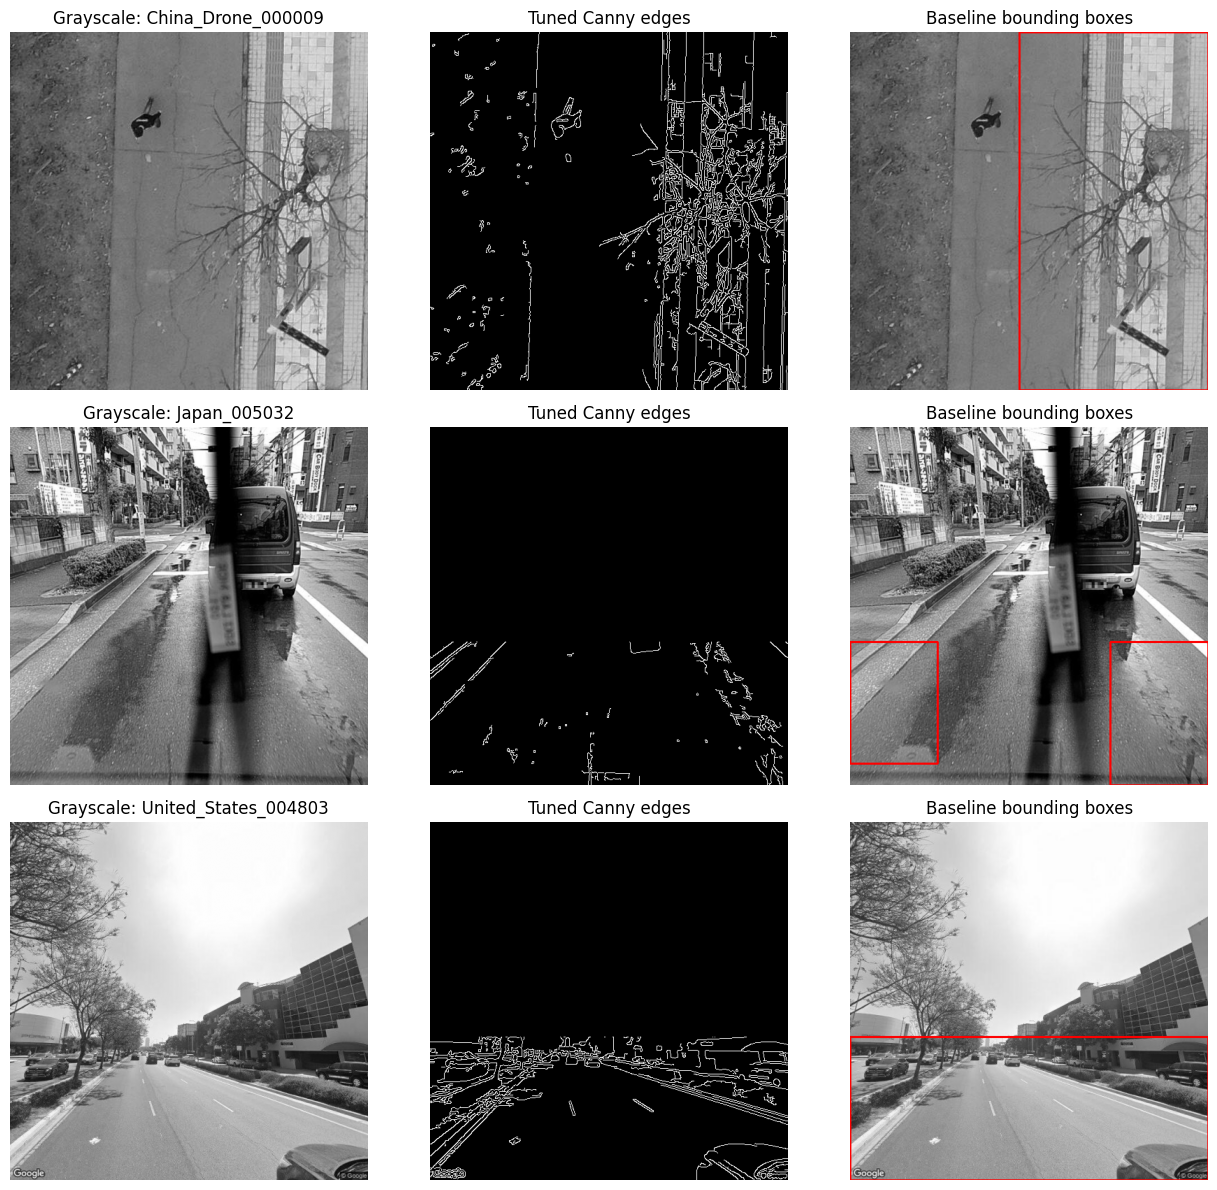

In [ ]:
# Member 2 - Display three Development examples (no Test images are used).
import matplotlib.pyplot as plt
M2_PREVIEW = [M2_DEV_GRAY[i] for i in np.linspace(0, len(M2_DEV_GRAY)-1, min(3,len(M2_DEV_GRAY)), dtype=int)]
fig, axes = plt.subplots(len(M2_PREVIEW), 3, figsize=(13, 4*len(M2_PREVIEW)), squeeze=False)
for i, path in enumerate(M2_PREVIEW):
    gray = read_gray_image(path)
    edges, boxes = baseline_predict(gray, path.stem, M2_FINAL_CONFIG)
    preview = cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB)
    for x1,y1,x2,y2 in boxes:
        cv2.rectangle(preview,(int(x1),int(y1)),(int(x2),int(y2)),(255,0,0),2)
    axes[i,0].imshow(gray,cmap='gray');axes[i,0].set_title('Grayscale: '+path.stem)
    axes[i,1].imshow(edges,cmap='gray');axes[i,1].set_title('Tuned Canny edges')
    axes[i,2].imshow(preview);axes[i,2].set_title('Baseline bounding boxes')
    for ax in axes[i]: ax.axis('off')
plt.tight_layout()
plt.show()


In [ ]:
# Member 2 - Convert baseline boxes from resized-image to original-image coordinates.
M2_META_BY_ID = M2_METADATA.set_index('image_id')
def m2_boxes_to_original(boxes, image_stem):
    if not boxes:
        return []
    row = M2_META_BY_ID.loc[image_stem]
    sx, sy = float(row.scale_x), float(row.scale_y)
    b = np.asarray(boxes, dtype=float) / np.array([sx, sy, sx, sy])
    b[:,[0,2]] = np.clip(b[:,[0,2]], 0, int(row.original_width))
    b[:,[1,3]] = np.clip(b[:,[1,3]], 0, int(row.original_height))
    return np.round(b[(b[:,2]>b[:,0]) & (b[:,3]>b[:,1])],2).tolist()

for path in M2_PREVIEW:
    gray = read_gray_image(path)
    _, boxes = baseline_predict(gray, path.stem, M2_FINAL_CONFIG)
    print(path.stem, 'resized boxes:', len(boxes), 'original boxes:', len(m2_boxes_to_original(boxes,path.stem)))


China_Drone_000009 resized boxes: 1 original boxes: 1
Japan_005032 resized boxes: 2 original boxes: 2
United_States_004803 resized boxes: 1 original boxes: 1


## Member 3 — Filtering and Contrast Enhancement

The original Member 3 filtering, contrast enhancement, tuning and visualization functions are retained. Existing Enhanced images are reused without overwriting them; only Development images are considered.


In [ ]:
# Member 3 — define paths (Drive is already mounted in the first cell).
from pathlib import Path
import json
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

M3_PROCESSED_DIR = Path('/content/drive/MyDrive/RoadGuard_Project/Dataset/Processed')
M3_SPLITS = ['Development']
M3_FIGURES_DIR = M3_PROCESSED_DIR / 'Member3_Figures_improved' / RUN_ID

for split in M3_SPLITS:
    if not (M3_PROCESSED_DIR / split / 'Grayscale').is_dir():
        raise FileNotFoundError(f'Missing folder: {M3_PROCESSED_DIR / split / "Grayscale"}')

M3_DEV_PATHS = sorted((M3_PROCESSED_DIR / 'Development' / 'Grayscale').glob('*.png'))
print('Development images:', len(M3_DEV_PATHS))

Development images: 5100


In [7]:
# Filtering methods (noise reduction).
def apply_filter(gray, method):
    if method == 'none':
        return gray.copy()
    if method == 'gaussian':
        return cv2.GaussianBlur(gray, (5, 5), 0)
    if method == 'median':
        return cv2.medianBlur(gray, 5)
    if method == 'bilateral':
        # Smooths flat asphalt texture while keeping crack edges sharp.
        return cv2.bilateralFilter(gray, d=9, sigmaColor=75, sigmaSpace=75)
    raise ValueError(f'Unknown filter: {method}')


# Contrast enhancement methods.
def apply_contrast(gray, method):
    if method == 'none':
        return gray.copy()
    if method == 'histeq':
        return cv2.equalizeHist(gray)
    if method.startswith('clahe'):
        clip = float(method.split('_')[1])
        clahe = cv2.createCLAHE(clipLimit=clip, tileGridSize=(8, 8))
        return clahe.apply(gray)
    raise ValueError(f'Unknown contrast method: {method}')


def enhance_image(gray, filter_method, contrast_method):
    """Filtering first (remove noise), then contrast enhancement (so noise is not amplified)."""
    if gray.ndim != 2 or gray.dtype != np.uint8:
        raise ValueError('Expected a 2-D uint8 grayscale image.')
    return apply_contrast(apply_filter(gray, filter_method), contrast_method)

In [ ]:
# Evaluation helpers: how well does an enhanced image separate damage from background?
def read_gray(path):
    gray = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if gray is None or gray.ndim != 2:
        raise ValueError(f'Cannot read grayscale image: {path}')
    return gray


def damage_mask_from_label(label_path, shape):
    """Build a mask of ground-truth boxes (YOLO normalized format) at the resized image size."""
    h, w = shape
    mask = np.zeros((h, w), dtype=bool)
    if not label_path.exists():
        return mask
    for line in label_path.read_text().split('\n'):
        values = line.split()
        if len(values) != 5:
            continue
        _, xc, yc, bw, bh = map(float, values)
        x1, x2 = int((xc - bw / 2) * w), int(np.ceil((xc + bw / 2) * w))
        y1, y2 = int((yc - bh / 2) * h), int(np.ceil((yc + bh / 2) * h))
        mask[max(y1, 0):min(y2, h), max(x1, 0):min(x2, w)] = True
    return mask


def image_scores(enhanced, damage_mask):
    gx = cv2.Sobel(enhanced, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(enhanced, cv2.CV_32F, 0, 1, ksize=3)
    grad = cv2.magnitude(gx, gy)
    background = ~damage_mask
    lap = np.abs(cv2.Laplacian(enhanced, cv2.CV_32F))
    return {
        # Edge strength inside damage boxes vs. background (higher = damage stands out more).
        'damage_separability': float(grad[damage_mask].mean() / (grad[background].mean() + 1e-6)),
        # Global RMS contrast.
        'rms_contrast': float(enhanced.std()),
        # High-frequency noise on the background (lower = cleaner).
        'background_noise': float(lap[background].mean()),
    }

In [ ]:
# Experiment: compare all filter x contrast combinations on a Development subset.
M3_FILTERS = ['none', 'gaussian', 'median', 'bilateral']
M3_CONTRASTS = ['none', 'histeq', 'clahe_2.0', 'clahe_3.0']
M3_SUBSET_SIZE = 300

rng = np.random.default_rng(42)
subset_idx = rng.choice(len(M3_DEV_PATHS), min(M3_SUBSET_SIZE, len(M3_DEV_PATHS)), replace=False)

# Keep only subset images that contain at least one damage box.
subset = []
for i in subset_idx:
    path = M3_DEV_PATHS[i]
    gray = read_gray(path)
    label_path = M3_PROCESSED_DIR / 'Development' / 'Labels' / (path.stem + '.txt')
    mask = damage_mask_from_label(label_path, gray.shape)
    if mask.any() and (~mask).any():
        subset.append((gray, mask))
print('Images used in the experiment:', len(subset))

rows = []
for f in M3_FILTERS:
    for c in M3_CONTRASTS:
        scores = [image_scores(enhance_image(g, f, c), m) for g, m in subset]
        rows.append({'filter': f, 'contrast': c, **pd.DataFrame(scores).mean().to_dict()})

M3_RESULTS = (pd.DataFrame(rows)
              .sort_values('damage_separability', ascending=False)
              .reset_index(drop=True))
M3_FIGURES_DIR.mkdir(parents=True, exist_ok=True)
M3_RESULTS.to_csv(M3_FIGURES_DIR / 'EXPERIMENT_member3_settings_comparison.csv', index=False)
M3_RESULTS.round(3)

Images used in the experiment: 216


,filter,contrast,damage_separability,rms_contrast,background_noise
0,none,clahe_3.0,1.068,61.054,48.628
1,none,histeq,1.022,74.758,42.264
2,none,clahe_2.0,1.010,59.904,41.251
3,gaussian,histeq,0.957,74.614,10.479
4,gaussian,clahe_3.0,0.948,57.196,10.807
5,median,clahe_3.0,0.914,57.067,12.391
6,median,histeq,0.913,74.705,11.702
7,gaussian,clahe_2.0,0.907,56.622,9.009
8,median,clahe_2.0,0.877,56.747,10.513
9,none,none,0.865,59.200,22.764


In [ ]:
# Select the best setting that applies BOTH a filter and a contrast method
# (highest damage separability). Baseline = original image (no filter, no contrast).
candidates = M3_RESULTS[(M3_RESULTS['filter'] != 'none') & (M3_RESULTS['contrast'] != 'none')]
best = candidates.iloc[0]
M3_FILTER, M3_CONTRAST = best['filter'], best['contrast']
baseline = M3_RESULTS[(M3_RESULTS['filter'] == 'none') & (M3_RESULTS['contrast'] == 'none')].iloc[0]

print(f'Selected: filter={M3_FILTER}, contrast={M3_CONTRAST}')
print(f"Damage separability: {baseline['damage_separability']:.3f} (original) -> {best['damage_separability']:.3f}")
print(f"RMS contrast:        {baseline['rms_contrast']:.2f} -> {best['rms_contrast']:.2f}")
print(f"Background noise:    {baseline['background_noise']:.2f} -> {best['background_noise']:.2f}")

Selected: filter=gaussian, contrast=histeq
Damage separability: 0.865 (original) -> 0.957
RMS contrast:        59.20 -> 74.61
Background noise:    22.76 -> 10.48


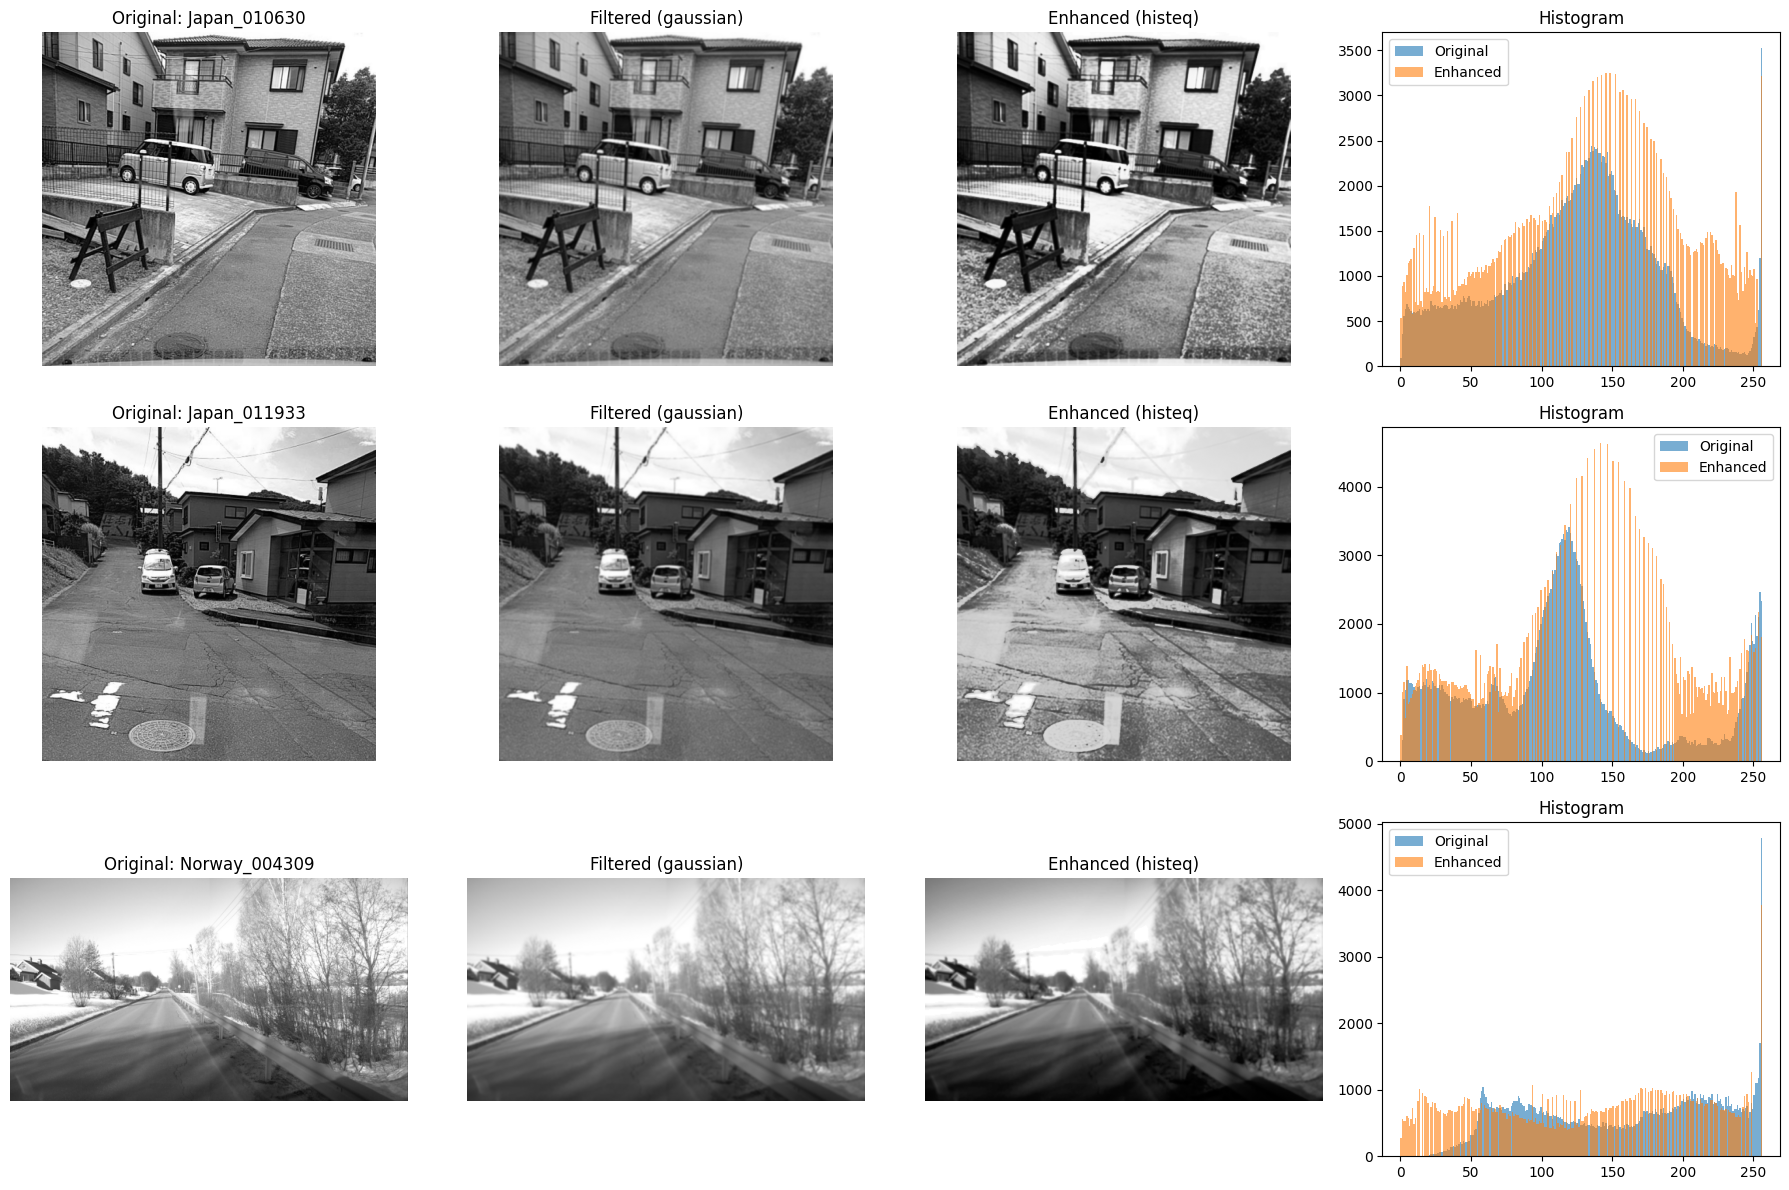

In [ ]:
# Save before/after figures for the report (Development images only).
preview_paths = [M3_DEV_PATHS[i] for i in rng.choice(len(M3_DEV_PATHS), 3, replace=False)]

fig, axes = plt.subplots(len(preview_paths), 4, figsize=(18, 4 * len(preview_paths)), squeeze=False)
for r, path in enumerate(preview_paths):
    gray = read_gray(path)
    filtered = apply_filter(gray, M3_FILTER)
    enhanced = apply_contrast(filtered, M3_CONTRAST)
    panels = [(gray, f'Original: {path.stem}'), (filtered, f'Filtered ({M3_FILTER})'),
              (enhanced, f'Enhanced ({M3_CONTRAST})')]
    for col, (img, title) in enumerate(panels):
        axes[r, col].imshow(img, cmap='gray', vmin=0, vmax=255)
        axes[r, col].set_title(title)
        axes[r, col].axis('off')
    axes[r, 3].hist(gray.ravel(), bins=256, range=(0, 256), alpha=0.6, label='Original')
    axes[r, 3].hist(enhanced.ravel(), bins=256, range=(0, 256), alpha=0.6, label='Enhanced')
    axes[r, 3].set_title('Histogram')
    axes[r, 3].legend()
plt.tight_layout()
plt.savefig(M3_FIGURES_DIR / 'before_after_enhancement.png', dpi=150, bbox_inches='tight')
plt.show()

### Member 3 - Save enhanced Development images to Enhanced-IMAGE (keep original Enhanced unchanged)


In [ ]:
# Member 3 - Save newly enhanced Development images in a separate folder.
# Existing Development/Enhanced images remain untouched.
M3_GRAY_DIR = M3_PROCESSED_DIR / 'Development' / 'Grayscale'
M3_ENH_DIR = M3_PROCESSED_DIR / 'Development' / 'Enhanced-IMAGE'
M3_ENH_DIR.mkdir(parents=True, exist_ok=True)

assert M3_DEV_PATHS, 'No Development grayscale images found'
assert 'M3_FILTER' in globals() and 'M3_CONTRAST' in globals(), 'Run Member 3 setting selection first'

for gray_path in tqdm(M3_DEV_PATHS, desc='Saving Enhanced-IMAGE (Development only)'):
    output_path = M3_ENH_DIR / gray_path.name
    if output_path.exists():
        continue  # Resume safely; do not overwrite already generated images.
    gray = read_gray(gray_path)
    enhanced = enhance_image(gray, M3_FILTER, M3_CONTRAST)
    if not cv2.imwrite(str(output_path), enhanced):
        raise IOError(f'Could not save: {output_path}')

missing = [p.name for p in M3_DEV_PATHS if not (M3_ENH_DIR / p.name).exists()]
assert not missing, f'Missing {len(missing)} enhanced images, e.g. {missing[:3]}'
print('New Development images saved to:', M3_ENH_DIR)
print('Image count:', len(M3_DEV_PATHS))
print('Existing Development/Enhanced and all Test images were not modified.')


Saving Enhanced-IMAGE (Development only):   0%|          | 0/5100 [00:00<?, ?it/s]

New Development images saved to: /content/drive/MyDrive/RoadGuard_Project/Dataset/Processed/Development/Enhanced-IMAGE
Image count: 5100
Existing Development/Enhanced and all Test images were not modified.


###Image Enhancement Quality Comparison

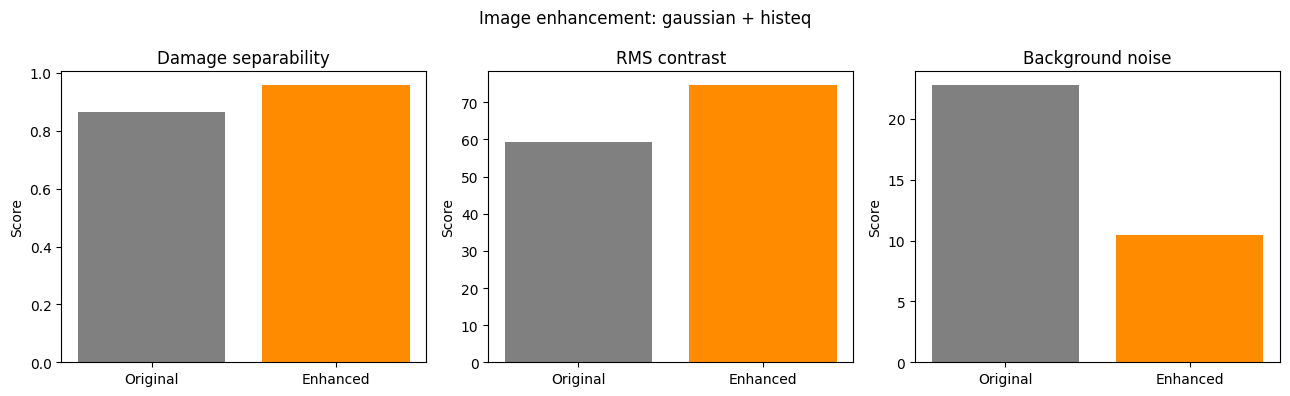

In [ ]:
M3_BASELINE_ROW = M3_RESULTS[
    (M3_RESULTS["filter"] == "none") &
    (M3_RESULTS["contrast"] == "none")
].iloc[0]

M3_SELECTED_ROW = M3_RESULTS[
    (M3_RESULTS["filter"] == M3_FILTER) &
    (M3_RESULTS["contrast"] == M3_CONTRAST)
].iloc[0]

M3_QUALITY_METRICS = [
    ("damage_separability", "Damage separability"),
    ("rms_contrast", "RMS contrast"),
    ("background_noise", "Background noise"),
]

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for ax, (column, title) in zip(axes, M3_QUALITY_METRICS):
    values = [
        M3_BASELINE_ROW[column],
        M3_SELECTED_ROW[column]
    ]

    ax.bar(
        ["Original", "Enhanced"],
        values,
        color=["gray", "darkorange"]
    )
    ax.set_title(title)
    ax.set_ylabel("Score")

fig.suptitle(
    f"Image enhancement: {M3_FILTER} + {M3_CONTRAST}"
)
plt.tight_layout()
plt.show()

## Member 4 — Adaptive Thresholding + Morphology + Canny

The classical segmentation branch uses new Enhanced-IMAGE images. The edge branch uses the tuned Canny configuration; candidate boxes are filtered by edge density and deduplicated by IoU. All parameter selection and evaluation below use Development only.


In [8]:
_m2_extract_damage_boxes = extract_damage_boxes

def m4_make_mask(
    gray,
    block_size,
    constant_c,
    polarity,
    kernel_size,
    close_iterations,
    road_top_fraction=0.0,
    min_component_pixels=20
):
    if gray.ndim != 2 or gray.dtype != np.uint8:
        raise ValueError("Expected a 2-D uint8 grayscale image.")

    if block_size < 3 or block_size % 2 == 0:
        raise ValueError("block_size must be an odd integer >= 3.")

    if kernel_size < 1 or kernel_size % 2 == 0:
        raise ValueError("kernel_size must be a positive odd integer.")

    if not 0.0 <= road_top_fraction < 1.0:
        raise ValueError("road_top_fraction must be between 0 and 1.")

    if min_component_pixels < 1:
        raise ValueError("min_component_pixels must be positive.")

    threshold_type = (
        cv2.THRESH_BINARY_INV
        if polarity == "dark"
        else cv2.THRESH_BINARY
    )

    mask = cv2.adaptiveThreshold(
        gray,
        255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        threshold_type,
        block_size,
        constant_c
    )

    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (kernel_size, kernel_size)
    )

    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_CLOSE,
        kernel,
        iterations=close_iterations
    )

    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_OPEN,
        kernel,
        iterations=1
    )

    # Remove the selected upper portion of the image
    cut_row = int(road_top_fraction * mask.shape[0])

    if cut_row > 0:
        mask[:cut_row, :] = 0

    # Remove small connected components efficiently
    count, component_labels, stats, _ = cv2.connectedComponentsWithStats(
        (mask > 0).astype(np.uint8),
        connectivity=8
    )

    keep_component = (
        stats[:, cv2.CC_STAT_AREA] >= min_component_pixels
    )
    keep_component[0] = False

    cleaned_mask = (
        keep_component[component_labels].astype(np.uint8) * 255
    )

    return cleaned_mask

def make_mask_v4(gray, image_stem, **config):
    # Drone images keep the full image because the camera angle differs
    road_top_fraction = (
        0.0 if "drone" in image_stem.lower()
        else config["road_top_fraction"]
    )

    shared = {
        "block_size": config["block_size"],
        "kernel_size": config["kernel_size"],
        "close_iterations": config["close_iterations"],
        "road_top_fraction": road_top_fraction,
        "min_component_pixels": config["min_component_pixels"],
    }

    dark_mask = m4_make_mask(
        gray,
        constant_c=config["constant_c"],
        polarity="dark",
        **shared
    )

    if config["polarity"] == "dark":
        return dark_mask

    bright_mask = m4_make_mask(
        gray,
        constant_c=-config["constant_c"],
        polarity="bright",
        **shared
    )

    if config["polarity"] == "bright":
        return bright_mask

    if config["polarity"] == "both":
        return np.maximum(dark_mask, bright_mask)

    raise ValueError(f"Unsupported polarity: {config['polarity']}")

def m4_ground_truth_boxes(label_path, image_shape):
    height, width = image_shape
    boxes = []

    for line in label_path.read_text(encoding="utf-8").splitlines():
        fields = line.split()

        if len(fields) != 5:
            continue

        _, x_center, y_center, box_width, box_height = map(
            float, fields
        )

        x1 = max(0, int((x_center - box_width / 2) * width))
        y1 = max(0, int((y_center - box_height / 2) * height))
        x2 = min(
            width,
            int(np.ceil((x_center + box_width / 2) * width))
        )
        y2 = min(
            height,
            int(np.ceil((y_center + box_height / 2) * height))
        )

        if x2 > x1 and y2 > y1:
            boxes.append([x1, y1, x2, y2])

    return boxes

def m4_iou(box_a, box_b):
    x1 = max(box_a[0], box_b[0])
    y1 = max(box_a[1], box_b[1])
    x2 = min(box_a[2], box_b[2])
    y2 = min(box_a[3], box_b[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)

    area_a = (
        max(0, box_a[2] - box_a[0]) *
        max(0, box_a[3] - box_a[1])
    )

    area_b = (
        max(0, box_b[2] - box_b[0]) *
        max(0, box_b[3] - box_b[1])
    )

    union = area_a + area_b - intersection

    return intersection / union if union else 0.0

def m4_count_matches(predicted, actual, iou_threshold=0.5):
    pairs = sorted(
        (
            (m4_iou(pred, truth), pred_i, truth_i)
            for pred_i, pred in enumerate(predicted)
            for truth_i, truth in enumerate(actual)
        ),
        reverse=True
    )

    used_predictions = set()
    used_truth = set()
    true_positives = 0

    for overlap, pred_i, truth_i in pairs:
        if overlap < iou_threshold:
            break

        if pred_i not in used_predictions and truth_i not in used_truth:
            used_predictions.add(pred_i)
            used_truth.add(truth_i)
            true_positives += 1

    false_positives = len(predicted) - true_positives
    false_negatives = len(actual) - true_positives

    return true_positives, false_positives, false_negatives

def prf(tp, fp, fn):
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )

    return precision, recall, f1

def m4i_components(binary, min_pixels=1):
    """Connected components (8-connectivity) -> boxes [x1, y1, x2, y2] and pixel counts."""
    count, _, stats, _ = cv2.connectedComponentsWithStats((binary > 0).astype(np.uint8), connectivity=8)
    boxes, pixels = [], []
    for x, y, w, h, area in stats[1:]:
        if area >= min_pixels and min(w, h) >= 2 and max(w / h, h / w) <= 100:
            boxes.append([int(x), int(y), int(x + w), int(y + h)])
            pixels.append(int(area))
    return boxes, pixels

def m4i_group_boxes(boxes, pixels, gap):
    """Group boxes that overlap or are closer than `gap` pixels (box coordinates only)."""
    b = np.asarray(boxes, dtype=float).reshape(-1, 4)
    p = np.asarray(pixels, dtype=float)
    while len(b) > 1:
        dx = np.maximum(0, np.maximum(b[:, None, 0], b[None, :, 0]) - np.minimum(b[:, None, 2], b[None, :, 2]))
        dy = np.maximum(0, np.maximum(b[:, None, 1], b[None, :, 1]) - np.minimum(b[:, None, 3], b[None, :, 3]))
        n_groups, group = connected_components((dx <= gap) & (dy <= gap), directed=False)
        if n_groups == len(b):
            break
        merged = np.zeros((n_groups, 4))
        merged[:, :2] = np.inf
        np.minimum.at(merged[:, 0], group, b[:, 0])
        np.minimum.at(merged[:, 1], group, b[:, 1])
        np.maximum.at(merged[:, 2], group, b[:, 2])
        np.maximum.at(merged[:, 3], group, b[:, 3])
        b, p = merged, np.bincount(group, weights=p, minlength=n_groups)
    return b.astype(int).tolist(), p.astype(int).tolist()

def m4i_segmentation_boxes(enhanced, stem):
    """Member 4 pipeline, unchanged: mask -> component boxes -> box scale 1.1."""
    mask = make_mask_v4(enhanced, stem, **M4I_SEG_CONFIG)
    p = M4I_SEG_BOX_PARAMS
    boxes, _ = m4i_components(mask, p['min_component_pixels'])
    area = mask.shape[0] * mask.shape[1]
    boxes = [b for b in boxes if (b[2] - b[0]) * (b[3] - b[1]) / area <= p['max_bbox_area_fraction']]
    return [expand_box(b, enhanced.shape, M4I_SEG_BOX_SCALE) for b in boxes], mask

def m4i_edge_boxes(gray, stem, cfg=None):
    """Canny edge branch (same steps and settings as the tuned Canny baseline)."""
    cfg = cfg or M4I_EDGE_CONFIG
    image = cv2.GaussianBlur(gray, (cfg['blur'],) * 2, 0) if cfg['blur'] else gray
    edges = cv2.Canny(image, cfg['low'], cfg['high'], apertureSize=3, L2gradient=True)
    if 'drone' not in stem.lower():
        edges[:int(edges.shape[0] * cfg['roi_top_fraction']), :] = 0
    boxes, pixels = m4i_components(edges, cfg['min_component_pixels'])
    boxes, pixels = m4i_group_boxes(boxes, pixels, cfg['merge_gap'])
    area = gray.shape[0] * gray.shape[1]
    keep = [i for i, b in enumerate(boxes) if pixels[i] >= cfg['min_group_pixels']
            and cfg['min_box_area_fraction'] <= (b[2] - b[0]) * (b[3] - b[1]) / area <= cfg['max_bbox_area_fraction']]
    keep = sorted(keep, key=lambda i: -(boxes[i][2] - boxes[i][0]) * (boxes[i][3] - boxes[i][1]))[:cfg['max_boxes']]
    boxes = [expand_box(boxes[i], gray.shape, cfg['box_scale']) for i in keep]
    return boxes, edges

def m4i_iou(a, b):
    ix = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0

def m4i_edge_density(box, edges):
    x1, y1 = int(box[0]), int(box[1])
    x2, y2 = int(np.ceil(box[2])), int(np.ceil(box[3]))
    region = edges[y1:y2, x1:x2]
    return float((region > 0).mean()) if region.size else 0.0

def m4i_combine(seg_boxes, edge_boxes, gray_edges, cfg):
    """Combination rule.

    min_edge_density : keep a segmentation box only if Canny edges cover at least this share of it.
    add_edge_boxes   : add edge-branch boxes that do not duplicate a kept segmentation box.
    dedupe_iou       : an edge box is a duplicate when its IoU with a kept box is >= this value.
    """
    kept = [b for b in seg_boxes if m4i_edge_density(b, gray_edges) >= cfg['min_edge_density']]
    if cfg['add_edge_boxes']:
        for b in edge_boxes:
            if all(m4i_iou(b, k) < cfg['dedupe_iou'] for k in kept):
                kept.append(b)
    return kept
M4I_SEG_CONFIG=dict(BEST_CONFIG)
M4I_SEG_BOX_SCALE=1.1
M4I_SEG_BOX_PARAMS={'min_component_pixels':20,'min_bbox_side':2,'max_bbox_area_fraction':0.8,'max_aspect_ratio':100.0}
M4I_EDGE_CONFIG={'low':50,'high':150,'blur':3,'min_component_pixels':40,'roi_top_fraction':0.6,'merge_gap':12,'min_group_pixels':600,'max_bbox_area_fraction':0.8,'min_box_area_fraction':0.0,'max_boxes':3,'box_scale':1.0}
M4I_EDGE_CONFIG.update({k:M2_FINAL_CONFIG[k] for k in M4I_EDGE_CONFIG if k in M2_FINAL_CONFIG})
M4I_EDGE_CONFIG['box_scale'] = 1.0  # Preserve Claude's winning tuned Canny box scale
print('Loaded saved configurations')


Loaded saved configurations


In [9]:
import json, pandas as pd
from pathlib import Path

# Latest saved run from Member 3 (filter/contrast selection)
m3_csv = sorted((PROCESSED / "Member3_Figures_improved").glob("*/EXPERIMENT_member3_settings_comparison.csv"))[-1]
m3_df = pd.read_csv(m3_csv)
best_row = m3_df[(m3_df["filter"] != "none") & (m3_df["contrast"] != "none")].iloc[0]
M3_FILTER, M3_CONTRAST = best_row["filter"], best_row["contrast"]

# Latest saved run from Member 4 (combination parameters)
m4_json = sorted((PROCESSED / "Member4_Improved_Results_improved").glob("*/EXPERIMENT_selected_configs.json"))[-1]
BEST_COMBO = json.loads(m4_json.read_text())["improved_combination"]

print("M3 file:", m3_csv)
print("M4 file:", m4_json)
print("Filter / Contrast:", M3_FILTER, M3_CONTRAST)
print("BEST_COMBO:", BEST_COMBO)

M3 file: /content/drive/MyDrive/RoadGuard_Project/Dataset/Processed/Member3_Figures_improved/Approved_Improved_20261123_071946/EXPERIMENT_member3_settings_comparison.csv
M4 file: /content/drive/MyDrive/RoadGuard_Project/Dataset/Processed/Member4_Improved_Results_improved/Approved_Improved_20261123_071946/EXPERIMENT_selected_configs.json
Filter / Contrast: gaussian histeq
BEST_COMBO: {'min_edge_density': 0.0, 'add_edge_boxes': True, 'dedupe_iou': 0.5}


### Development-only branch checkpoint


In [ ]:
# Build a stable split and incremental branch cache. Saved on Drive after every image.
DEV_PATHS=sorted((PROCESSED/'Development'/'Enhanced-IMAGE').glob('*.png'))
# No Test images loaded: Member 5 handles the Test set separately.
assert DEV_PATHS, 'No Development Enhanced-IMAGE PNG images; run Member 3 first'
assert len(DEV_PATHS)==len(list((PROCESSED/'Development'/'Grayscale').glob('*.png')))
rng=np.random.default_rng(42)
tune_ids=set(rng.choice(np.arange(len(DEV_PATHS)),size=min(1000,len(DEV_PATHS)),replace=False).tolist())
META=pd.read_csv(PROCESSED/'Metadata.csv').set_index('image_id')
print('Development:',len(DEV_PATHS),'Tuning:',len(tune_ids))
# Optional runtime controls
RUN_TEST=False
EVAL_TEST_IF_LABELS_EXIST=False

def read_pair(path,split):
 enhanced=read_gray_image(path)
 gray=read_gray_image(PROCESSED/split/'Grayscale'/path.name)
 if enhanced.shape!=gray.shape: raise ValueError('Image shape mismatch: '+path.name)
 return enhanced,gray

def to_original(boxes,stem):
 if not boxes:return []
 row=META.loc[stem]; sx,sy=float(row.scale_x),float(row.scale_y)
 b=np.asarray(boxes,dtype=float)/np.array([sx,sy,sx,sy]);w,h=int(row.original_width),int(row.original_height)
 b[:,[0,2]]=np.clip(b[:,[0,2]],0,w);b[:,[1,3]]=np.clip(b[:,[1,3]],0,h)
 return np.round(b[(b[:,2]>b[:,0])&(b[:,3]>b[:,1])],2).tolist()

def branch_row(path,split):
 stem=path.stem; enhanced,gray=read_pair(path,split)
 _,baseline=baseline_predict(gray,stem,M2_FINAL_CONFIG)
 seg,_=m4i_segmentation_boxes(enhanced,stem)
 edge,_=m4i_edge_boxes(gray,stem)
 density_edges=cv2.Canny(cv2.GaussianBlur(gray,(3,3),0),50,150,L2gradient=True)
 density=[m4i_edge_density(b,density_edges) for b in seg]
 lab=PROCESSED/split/'Labels'/(stem+'.txt')
 gt=m4_ground_truth_boxes(lab,gray.shape) if lab.exists() else None
 return {'image_id':stem,'split':split,'baseline':baseline,'seg':seg,'edge':edge,'density':density,'gt':gt,
         'baseline_original':to_original(baseline,stem),'seg_original':to_original(seg,stem),'edge_original':to_original(edge,stem)}

def checkpoint(split,paths):
 file=OUT/f'{split.lower()}_branches_checkpoint.jsonl'
 seen=set()
 if file.exists():
  with file.open() as f:
   for line in f:
    try:seen.add(json.loads(line)['image_id'])
    except Exception:pass
 print(split,'already checkpointed:',len(seen))
 with file.open('a',encoding='utf-8') as f:
  for path in tqdm(paths,desc=f'{split} checkpoint'):
   if path.stem in seen:continue
   row=branch_row(path,split)
   f.write(json.dumps(row)+'\n');f.flush()
 print('Saved',file)
 return file

def load_rows(file):
 with file.open(encoding='utf-8') as f:return [json.loads(line) for line in f if line.strip()]
DEV_FILE=checkpoint('Development',DEV_PATHS)


Development: 5100 Tuning: 1000
Development already checkpointed: 0


Development checkpoint:   0%|          | 0/5100 [00:00<?, ?it/s]

Saved /content/drive/MyDrive/RoadGuard_Project/Dataset/Processed/Member4_Improved_Results_improved/Approved_Improved_20261123_071946/development_branches_checkpoint.jsonl


### Select combination parameters on Development tuning


In [ ]:
# Select combination only on the 1,000-image Development tuning subset.
import itertools
rows=load_rows(DEV_FILE)
assert len(rows)==len(DEV_PATHS),'Incomplete Development checkpoint'
tune_stems={DEV_PATHS[i].stem for i in tune_ids}
TUNE=[r for r in rows if r['image_id'] in tune_stems]
VAL=[r for r in rows if r['image_id'] not in tune_stems]
def combine_cached(r,cfg):
 kept=[b for b,d in zip(r['seg'],r['density']) if d>=cfg['min_edge_density']]
 if cfg['add_edge_boxes']:
  for b in r['edge']:
   if all(m4i_iou(b,k)<cfg['dedupe_iou'] for k in kept):kept.append(b)
 return kept

def metrics(rows,predict):
 tp=fp=fn=n=0; missing=0
 for r in rows:
  if r['gt'] is None:missing+=1;continue
  pred=predict(r)
  a,b,c=m4_count_matches(pred,r['gt'],iou_threshold=0.5)
  tp+=a;fp+=b;fn+=c;n+=len(pred)
 p,rec,f1=prf(tp,fp,fn)
 return dict(images_evaluated=len(rows)-missing,missing_labels=missing,TP=tp,FP=fp,FN=fn,precision=p,recall=rec,F1_at_0_5=f1,boxes_per_image=n/max(len(rows)-missing,1))
GRID=[dict(min_edge_density=d,add_edge_boxes=a,dedupe_iou=q) for d,a,q in itertools.product([0,0.02,0.04,0.08,0.15],[False,True],[0.3,0.5]) if a or q==0.5]
search=[]
for cfg in tqdm(GRID,desc='Tuning combination'):
 result=metrics(TUNE,lambda r:combine_cached(r,cfg))
 search.append({**cfg,**result})
search_df=pd.DataFrame(search).sort_values('F1_at_0_5',ascending=False,kind='stable')
search_df.to_csv(OUT/'EXPERIMENT_combination_tuning.csv',index=False)
BEST_COMBO={k:(v.item() if hasattr(v,'item') else v) for k,v in search_df.iloc[0][['min_edge_density','add_edge_boxes','dedupe_iou']].to_dict().items()}
(OUT/'EXPERIMENT_selected_configs.json').write_text(json.dumps({'baseline':M2_FINAL_CONFIG,'member4':BEST_CONFIG,'improved_combination':BEST_COMBO,'tuned_on':'Development tuning (1000)','test_used_for_tuning':False},indent=2))
print('Selected combination:',BEST_COMBO)
display(search_df.head(10))


Tuning combination:   0%|          | 0/15 [00:00<?, ?it/s]

Selected combination: {'min_edge_density': 0.0, 'add_edge_boxes': True, 'dedupe_iou': 0.5}


,min_edge_density,add_edge_boxes,dedupe_iou,images_evaluated,missing_labels,TP,FP,FN,precision,recall,F1_at_0_5,boxes_per_image
2,0.00,True,0.5,1000,0,130,2609,1577,0.047463,0.076157,0.058480,2.739
1,0.00,True,0.3,1000,0,117,2422,1590,0.046081,0.068541,0.055111,2.539
5,0.02,True,0.5,1000,0,109,2155,1598,0.048145,0.063855,0.054898,2.264
0,0.00,False,0.5,1000,0,110,2252,1597,0.046571,0.064441,0.054067,2.362
11,0.08,True,0.5,1000,0,85,1405,1622,0.057047,0.049795,0.053175,1.490
10,0.08,True,0.3,1000,0,81,1298,1626,0.058738,0.047452,0.052495,1.379
14,0.15,True,0.5,1000,0,73,1033,1634,0.066004,0.042765,0.051902,1.106
8,0.04,True,0.5,1000,0,94,1826,1613,0.048958,0.055067,0.051833,1.920
13,0.15,True,0.3,1000,0,72,1017,1635,0.066116,0.042179,0.051502,1.089
4,0.02,True,0.3,1000,0,95,1975,1612,0.045894,0.055653,0.050304,2.070


### Compare Baseline, Adaptive + Morphology and Improved on Development


In [ ]:
# Official Development comparison on the same 4,100 held-out images.
METHODS={'Tuned Canny baseline':lambda r:r['baseline'],
         'Member 4 Adaptive + Morphology':lambda r:r['seg'],
         'Improved Adaptive + Canny':lambda r:combine_cached(r,BEST_COMBO)}
results=[]
for split_name,part in [('Development tuning',TUNE),('Development validation',VAL),('Development all',rows)]:
 for name,predict in METHODS.items():results.append({'split':split_name,'method':name,**metrics(part,predict)})
RESULTS=pd.DataFrame(results)
RESULTS.to_csv(OUT/'EXPERIMENT_development_metrics.csv',index=False)
display(RESULTS.round(5))
print('Saved metrics to',OUT)


,split,method,images_evaluated,missing_labels,TP,FP,FN,precision,recall,F1_at_0_5,boxes_per_image
0,Development tuning,Tuned Canny baseline,1000,0,73,902,1634,0.07487,0.04277,0.05444,0.97500
1,Development tuning,Member 4 Adaptive + Morphology,1000,0,110,2252,1597,0.04657,0.06444,0.05407,2.36200
2,Development tuning,Improved Adaptive + Canny,1000,0,130,2609,1577,0.04746,0.07616,0.05848,2.73900
3,Development validation,Tuned Canny baseline,4100,0,228,3684,6910,0.05828,0.03194,0.04127,0.95415
4,Development validation,Member 4 Adaptive + Morphology,4100,0,359,9153,6779,0.03774,0.05029,0.04312,2.32000
5,Development validation,Improved Adaptive + Canny,4100,0,415,10591,6723,0.03771,0.05814,0.04575,2.68439
6,Development all,Tuned Canny baseline,5100,0,301,4586,8544,0.06159,0.03403,0.04384,0.95824
7,Development all,Member 4 Adaptive + Morphology,5100,0,469,11405,8376,0.03950,0.05302,0.04527,2.32824
8,Development all,Improved Adaptive + Canny,5100,0,545,13200,8300,0.03965,0.06162,0.04825,2.69510


Saved metrics to /content/drive/MyDrive/RoadGuard_Project/Dataset/Processed/Member4_Improved_Results_improved/Approved_Improved_20261123_071946


###Pipeline Visualisation

China_Drone_000009: 6 predicted boxes
China_Drone_000011: 1 predicted boxes
China_Drone_000030: 1 predicted boxes


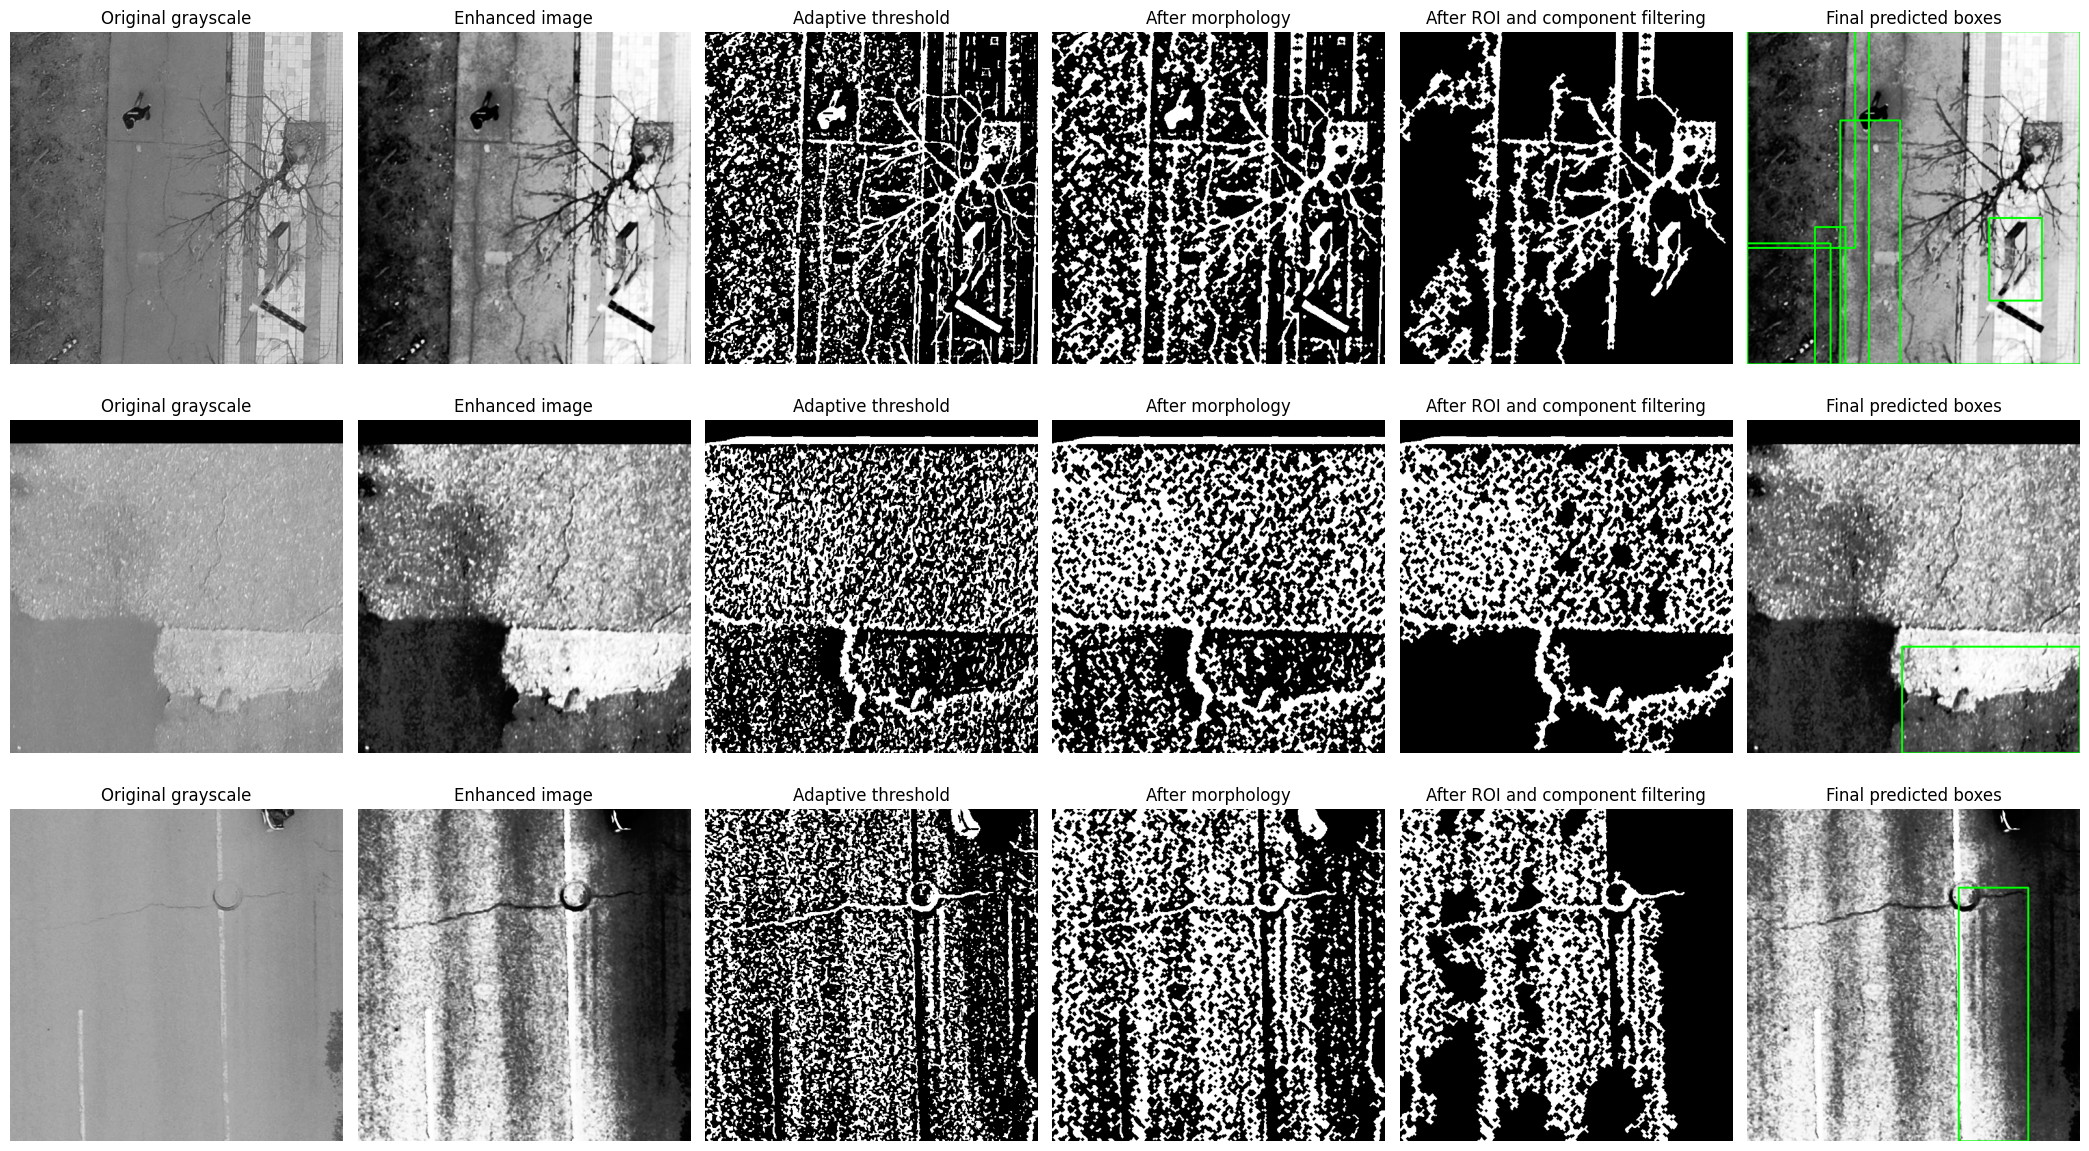

In [ ]:
import matplotlib.pyplot as plt
import cv2
import numpy as np

# Select labeled Development images from the validation portion.
M5_MEMBER4_PREVIEW_PATHS = []

for index, path in enumerate(DEV_PATHS):
    if index in tune_ids:
        continue

    label_path = PROCESSED / "Development" / "Labels" / f"{path.stem}.txt"
    if label_path.is_file() and label_path.read_text(encoding="utf-8").strip():
        M5_MEMBER4_PREVIEW_PATHS.append(path)

    if len(M5_MEMBER4_PREVIEW_PATHS) == 3:
        break

if not M5_MEMBER4_PREVIEW_PATHS:
    raise ValueError("No labeled Development validation images were found.")


def m5_member4_preview_stages(enhanced, stem, config):
    # Reproduce the selected adaptive-threshold polarity.
    if config["polarity"] in ("dark", "both"):
        dark_mask = cv2.adaptiveThreshold(
            enhanced,
            255,
            cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
            cv2.THRESH_BINARY_INV,
            config["block_size"],
            config["constant_c"]
        )

    if config["polarity"] in ("bright", "both"):
        bright_mask = cv2.adaptiveThreshold(
            enhanced,
            255,
            cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
            cv2.THRESH_BINARY,
            config["block_size"],
            -config["constant_c"]
        )

    if config["polarity"] == "dark":
        threshold_mask = dark_mask
    elif config["polarity"] == "bright":
        threshold_mask = bright_mask
    elif config["polarity"] == "both":
        threshold_mask = np.maximum(dark_mask, bright_mask)
    else:
        raise ValueError(f"Unsupported polarity: {config['polarity']}")

    # Apply the selected morphological operations.
    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (config["kernel_size"], config["kernel_size"])
    )

    morph_mask = cv2.morphologyEx(
        threshold_mask,
        cv2.MORPH_CLOSE,
        kernel,
        iterations=config["close_iterations"]
    )

    morph_mask = cv2.morphologyEx(
        morph_mask,
        cv2.MORPH_OPEN,
        kernel,
        iterations=1
    )

    # Apply the selected road-region crop; keep the full image for drone images.
    road_top_fraction = (
        0.0 if "drone" in stem.lower()
        else config["road_top_fraction"]
    )

    roi_mask = morph_mask.copy()
    cut_row = int(road_top_fraction * roi_mask.shape[0])

    if cut_row > 0:
        roi_mask[:cut_row, :] = 0

    # Remove connected components below the selected pixel threshold.
    count, component_labels, stats, _ = cv2.connectedComponentsWithStats(
        (roi_mask > 0).astype(np.uint8),
        connectivity=8
    )

    keep_component = (
        stats[:, cv2.CC_STAT_AREA]
        >= config["min_component_pixels"]
    )
    keep_component[0] = False

    cleaned_mask = (
        keep_component[component_labels].astype(np.uint8) * 255
    )

    return threshold_mask, morph_mask, cleaned_mask


fig, axes = plt.subplots(
    len(M5_MEMBER4_PREVIEW_PATHS),
    6,
    figsize=(21, 4 * len(M5_MEMBER4_PREVIEW_PATHS)),
    squeeze=False
)

for row, enhanced_path in enumerate(M5_MEMBER4_PREVIEW_PATHS):
    stem = enhanced_path.stem

    enhanced = read_gray_image(enhanced_path)
    gray_path = PROCESSED / "Development" / "Grayscale" / enhanced_path.name
    original_gray = read_gray_image(gray_path)

    threshold_mask, morph_mask, cleaned_mask = m5_member4_preview_stages(
        enhanced,
        stem,
        M4I_SEG_CONFIG
    )

    predicted_boxes, _ = m4i_segmentation_boxes(enhanced, stem)

    final_overlay = cv2.cvtColor(enhanced, cv2.COLOR_GRAY2RGB)

    for box in predicted_boxes:
        x1, y1, x2, y2 = [int(round(value)) for value in box]
        cv2.rectangle(final_overlay, (x1, y1), (x2, y2), (0, 255, 0), 2)

    panels = [
        (original_gray, "Original grayscale", "gray"),
        (enhanced, "Enhanced image", "gray"),
        (threshold_mask, "Adaptive threshold", "gray"),
        (morph_mask, "After morphology", "gray"),
        (cleaned_mask, "After ROI and component filtering", "gray"),
        (final_overlay, "Final predicted boxes", None),
    ]

    for column, (image, title, color_map) in enumerate(panels):
        axes[row, column].imshow(image, cmap=color_map)
        axes[row, column].set_title(title)
        axes[row, column].axis("off")

    print(f"{stem}: {len(predicted_boxes)} predicted boxes")

plt.tight_layout()
plt.show()

### Export Development predictions for Member 5


In [ ]:
# Save complete predictions for Development, in original-image coordinates.
def save_prediction_rows(split,records):
 for method,predict in METHODS.items():
  key={'Tuned Canny baseline':'baseline','Member 4 Adaptive + Morphology':'member4','Improved Adaptive + Canny':'improved'}[method]
  output=[]
  for r in tqdm(records,desc=split+' '+key):
   output.append({'image_id':r['image_id'],'boxes_resized_xyxy':predict(r),'boxes_original_xyxy':to_original(predict(r),r['image_id'])})
  # Member 2 predictions live beside other Processed result folders.
  if key == 'baseline':
   method_dir = PROCESSED / 'RoadGuard_Canny_Baseline_improved' / RUN_ID
   method_dir.mkdir(parents=True, exist_ok=True)
  else:
   method_dir = OUT
  path=method_dir/f'EXPERIMENT_{split.lower()}_{key}_predictions.json'
  path.write_text(json.dumps({'method':method,'dataset_split':split,'image_count':len(output),'coordinate_format':'xyxy','images':output}))
  print('Saved',path.name)
save_prediction_rows('Development',rows)


Development baseline:   0%|          | 0/5100 [00:00<?, ?it/s]

Saved EXPERIMENT_development_baseline_predictions.json


Development member4:   0%|          | 0/5100 [00:00<?, ?it/s]

Saved EXPERIMENT_development_member4_predictions.json


Development improved:   0%|          | 0/5100 [00:00<?, ?it/s]

Saved EXPERIMENT_development_improved_predictions.json


## Member 5 — Original code (unchanged)

**Stop here when running Members 2–4.** The following six cells are identical to RoadGuard (6).ipynb and include Test execution. Member 5 should update the evaluation inputs to the approved prediction methods before producing official final Test results.


## Member 5 - Final Test Evaluation

###Test Set and Label Validation

In [10]:
from pathlib import Path
import json
import cv2
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

M5_TEST_GRAY_DIR = PROCESSED / "Test" / "Grayscale"
M5_TEST_LABELS_DIR = PROCESSED / "Test" / "Labels"

if not M5_TEST_GRAY_DIR.is_dir():
    raise FileNotFoundError(f"Missing Test grayscale folder: {M5_TEST_GRAY_DIR}")

if not M5_TEST_LABELS_DIR.is_dir():
    raise FileNotFoundError(f"Missing Test labels folder: {M5_TEST_LABELS_DIR}")

M5_TEST_PATHS = sorted(M5_TEST_GRAY_DIR.glob("*.png"))

if len(M5_TEST_PATHS) != 900:
    raise ValueError(f"Expected 900 Test images, found {len(M5_TEST_PATHS)}")

M5_MISSING_LABELS = [
    path.stem for path in M5_TEST_PATHS
    if not (M5_TEST_LABELS_DIR / f"{path.stem}.txt").is_file()
]

if M5_MISSING_LABELS:
    raise FileNotFoundError(
        f"Missing labels for {len(M5_MISSING_LABELS)} images. "
        f"Examples: {M5_MISSING_LABELS[:10]}"
    )

M5_OUTPUT_DIR = Path(OUT) / "Member5_Final_Test_Evaluation"
M5_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

M5_PREDICTIONS = {}

print(f"Test images: {len(M5_TEST_PATHS)}")
print(f"Labels checked: {len(M5_TEST_PATHS)}")
print(f"Output folder: {M5_OUTPUT_DIR}")

Test images: 900
Labels checked: 900
Output folder: /content/drive/MyDrive/RoadGuard_Project/Dataset/Processed/Member4_Improved_Results_improved/Approved_Improved_20261123_134522/Member5_Final_Test_Evaluation


###Tuned Canny Baseline Evaluation

In [11]:
M5_PREDICTIONS["Tuned Canny Baseline"] = {}

for image_path in tqdm(M5_TEST_PATHS, desc="Evaluating Tuned Canny"):
    stem = image_path.stem
    gray = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)

    if gray is None:
        raise ValueError(f"Could not read image: {image_path}")

    label_path = M5_TEST_LABELS_DIR / f"{stem}.txt"
    actual_boxes = m4_ground_truth_boxes(label_path, gray.shape)

    _, predicted_boxes = baseline_predict(
        gray,
        stem,
        M2_FINAL_CONFIG
    )

    M5_PREDICTIONS["Tuned Canny Baseline"][stem] = {
        "predicted": predicted_boxes,
        "actual": actual_boxes,
    }

print("Tuned Canny Baseline evaluation finished.")
print(
    "Images evaluated:",
    len(M5_PREDICTIONS["Tuned Canny Baseline"])
)

Evaluating Tuned Canny:   0%|          | 0/900 [00:00<?, ?it/s]

Tuned Canny Baseline evaluation finished.
Images evaluated: 900


###Member 5 — Member 4 Current Method Evaluation

In [12]:
M5_PREDICTIONS["Member 4 Current Method"] = {}

for image_path in tqdm(M5_TEST_PATHS, desc="Evaluating Member 4"):
    stem = image_path.stem
    gray = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)

    if gray is None:
        raise ValueError(f"Could not read image: {image_path}")

    enhanced = enhance_image(
        gray,
        M3_FILTER,
        M3_CONTRAST
    )

    label_path = M5_TEST_LABELS_DIR / f"{stem}.txt"
    actual_boxes = m4_ground_truth_boxes(label_path, gray.shape)

    predicted_boxes, _ = m4i_segmentation_boxes(enhanced, stem)

    M5_PREDICTIONS["Member 4 Current Method"][stem] = {
        "predicted": predicted_boxes,
        "actual": actual_boxes,
    }

print("Member 4 Current Method evaluation finished.")
print("Images evaluated:", len(M5_PREDICTIONS["Member 4 Current Method"]))

Evaluating Member 4:   0%|          | 0/900 [00:00<?, ?it/s]

Member 4 Current Method evaluation finished.
Images evaluated: 900


###Improved Pipeline Evaluation

In [13]:
M5_PREDICTIONS["Improved Adaptive + Morphology + Canny"] = {}

for image_path in tqdm(
    M5_TEST_PATHS,
    desc="Evaluating Improved Pipeline"
):
    stem = image_path.stem

    gray = cv2.imread(
        str(image_path),
        cv2.IMREAD_GRAYSCALE
    )

    if gray is None:
        raise ValueError(f"Could not read image: {image_path}")

    enhanced = enhance_image(
        gray,
        M3_FILTER,
        M3_CONTRAST
    )

    label_path = M5_TEST_LABELS_DIR / f"{stem}.txt"
    actual_boxes = m4_ground_truth_boxes(
        label_path,
        gray.shape
    )

    # Keep only the boxes returned by each function.
    segmentation_boxes, _ = m4i_segmentation_boxes(
        enhanced,
        stem
    )

    edge_boxes, _ = m4i_edge_boxes(
        gray,
        stem
    )

    gray_for_edges = cv2.GaussianBlur(
        gray,
        (3, 3),
        0
    )

    # Use a different name so it does not overwrite the canny_edges function.
    canny_edge_map = cv2.Canny(
        gray_for_edges,
        50,
        150,
        L2gradient=True
    )

    predicted_boxes = m4i_combine(
        segmentation_boxes,
        edge_boxes,
        canny_edge_map,
        BEST_COMBO
    )

    M5_PREDICTIONS[
        "Improved Adaptive + Morphology + Canny"
    ][stem] = {
        "predicted": predicted_boxes,
        "actual": actual_boxes,
    }

print("Improved Pipeline evaluation finished.")
print(
    "Images evaluated:",
    len(M5_PREDICTIONS["Improved Adaptive + Morphology + Canny"])
)

Evaluating Improved Pipeline:   0%|          | 0/900 [00:00<?, ?it/s]

Improved Pipeline evaluation finished.
Images evaluated: 900


In [14]:
def m5_normalize_box(box):
    try:
        x1, y1, x2, y2 = [float(v) for v in box]
    except (TypeError, ValueError):
        return None
    if not np.all(np.isfinite([x1, y1, x2, y2])):
        return None
    if x2 <= x1 or y2 <= y1:
        return None
    return [x1, y1, x2, y2]

###Final Test Set Comparison and Results Export

In [15]:
print({method: len(results) for method, results in M5_PREDICTIONS.items()})

{'Tuned Canny Baseline': 900, 'Member 4 Current Method': 900, 'Improved Adaptive + Morphology + Canny': 900}


In [16]:
for method_name, image_results in M5_PREDICTIONS.items():
    for stem, result in image_results.items():
        result["predicted"] = [
            box
            for raw_box in result["predicted"]
            if (box := m5_normalize_box(raw_box)) is not None
        ]

        result["actual"] = [
            box
            for raw_box in result["actual"]
            if (box := m5_normalize_box(raw_box)) is not None
        ]

print("Box formats normalized for all methods.")

for method_name, image_results in M5_PREDICTIONS.items():
    first_stem = next(iter(image_results))
    print(
        method_name,
        "example prediction:",
        image_results[first_stem]["predicted"][:2],
        "| example label:",
        image_results[first_stem]["actual"][:2]
    )

Box formats normalized for all methods.
Tuned Canny Baseline example prediction: [] | example label: [[1.0, 30.0, 84.0, 54.0], [8.0, 0.0, 80.0, 455.0]]
Member 4 Current Method example prediction: [[109.39999999999998, 0.0, 386.6, 512.0], [330.35, 0.0, 512.0, 512.0]] | example label: [[1.0, 30.0, 84.0, 54.0], [8.0, 0.0, 80.0, 455.0]]
Improved Adaptive + Morphology + Canny example prediction: [[109.39999999999998, 0.0, 386.6, 512.0], [330.35, 0.0, 512.0, 512.0]] | example label: [[1.0, 30.0, 84.0, 54.0], [8.0, 0.0, 80.0, 455.0]]


###Member 5 — Validation IoU Threshold Analysis

In [ ]:
M5_IOU_THRESHOLDS = [0.1, 0.2, 0.3, 0.4, 0.5]

if len(VAL) != 4100:
    raise ValueError(f"Expected 4,100 validation images, found {len(VAL)}")

if any(row["gt"] is None for row in VAL):
    raise ValueError("Some validation images are missing ground-truth labels.")

M5_VALIDATION_METHODS = {
    "Tuned Canny Baseline": lambda row: row["baseline"],
    "Member 4 Current Method": lambda row: row["seg"],
    "Improved Pipeline": lambda row: combine_cached(row, BEST_COMBO),
}

M5_IOU_ROWS = []

for threshold in M5_IOU_THRESHOLDS:
    for method_name, predict in M5_VALIDATION_METHODS.items():
        total_tp = 0
        total_fp = 0
        total_fn = 0
        total_boxes = 0

        for row in VAL:
            predicted_boxes = predict(row)
            actual_boxes = row["gt"]

            tp, fp, fn = m4_count_matches(
                predicted_boxes,
                actual_boxes,
                iou_threshold=threshold
            )

            total_tp += tp
            total_fp += fp
            total_fn += fn
            total_boxes += len(predicted_boxes)

        precision, recall, f1_score = prf(
            total_tp,
            total_fp,
            total_fn
        )

        M5_IOU_ROWS.append({
            "IoU_threshold": threshold,
            "method": method_name,
            "images_evaluated": len(VAL),
            "ground_truth_boxes": sum(len(row["gt"]) for row in VAL),
            "TP": total_tp,
            "FP": total_fp,
            "FN": total_fn,
            "precision": precision,
            "recall": recall,
            "F1_score": f1_score,
            "boxes_per_image": total_boxes / len(VAL),
        })

M5_VALIDATION_IOU_RESULTS = pd.DataFrame(M5_IOU_ROWS)

# Compact table for the report: F1 at each IoU threshold.
M5_VALIDATION_F1_TABLE = (
    M5_VALIDATION_IOU_RESULTS
    .pivot(
        index="IoU_threshold",
        columns="method",
        values="F1_score"
    )
    .mul(100)
)

print("Development Validation images:", len(VAL))
print("Validation ground-truth boxes:", sum(len(row["gt"]) for row in VAL))
print("F1-score by IoU threshold (%):")
display(M5_VALIDATION_F1_TABLE.round(2))

# Detailed counts and metrics at the primary IoU threshold.
print("Full metrics at IoU = 0.5:")
display(
    M5_VALIDATION_IOU_RESULTS[
        M5_VALIDATION_IOU_RESULTS["IoU_threshold"] == 0.5
    ].round(4)
)

M5_VALIDATION_IOU_RESULTS.to_csv(
    OUT / "member5_validation_iou_threshold_details.csv",
    index=False
)

M5_VALIDATION_F1_TABLE.to_csv(
    OUT / "member5_validation_f1_by_iou.csv"
)

print("Validation IoU analysis saved to:", OUT)

Development Validation images: 4100
Validation ground-truth boxes: 7138
F1-score by IoU threshold (%):


method,Improved Pipeline,Member 4 Current Method,Tuned Canny Baseline
IoU_threshold,,,
0.1,21.31,20.98,20.38
0.2,13.82,13.66,12.72
0.3,9.48,9.24,8.43
0.4,6.65,6.41,5.70
0.5,4.57,4.31,4.13


Full metrics at IoU = 0.5:


,IoU_threshold,method,images_evaluated,ground_truth_boxes,TP,FP,FN,precision,recall,F1_score,boxes_per_image
12,0.5,Tuned Canny Baseline,4100,7138,228,3684,6910,0.0583,0.0319,0.0413,0.9541
13,0.5,Member 4 Current Method,4100,7138,359,9153,6779,0.0377,0.0503,0.0431,2.3200
14,0.5,Improved Pipeline,4100,7138,415,10591,6723,0.0377,0.0581,0.0457,2.6844


Validation IoU analysis saved to: /content/drive/MyDrive/RoadGuard_Project/Dataset/Processed/Member4_Improved_Results_improved/Approved_Improved_20261123_071946


###F1-score Across IoU Thresholds

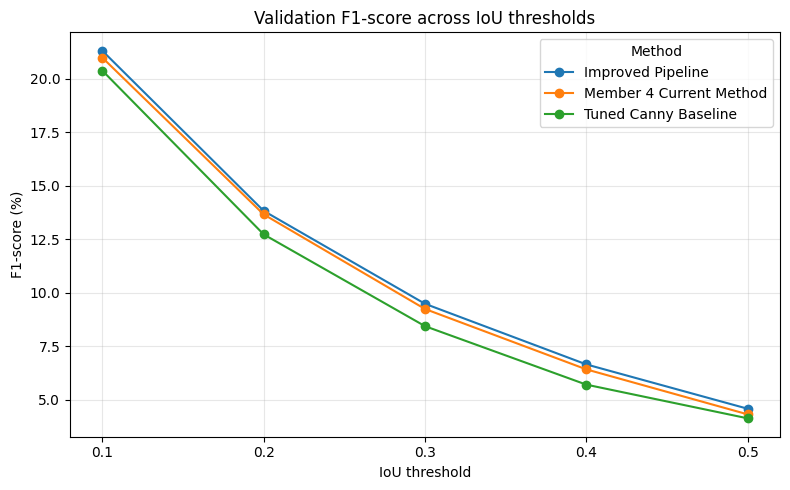

In [ ]:
import matplotlib.pyplot as plt

ax = M5_VALIDATION_F1_TABLE.plot(
    marker="o",
    figsize=(8, 5)
)

ax.set_title("Validation F1-score across IoU thresholds")
ax.set_xlabel("IoU threshold")
ax.set_ylabel("F1-score (%)")
ax.set_xticks(M5_IOU_THRESHOLDS)
ax.grid(True, alpha=0.3)
ax.legend(title="Method")
plt.tight_layout()
plt.show()

In [18]:
M5_ROWS = []

for method_name, image_results in M5_PREDICTIONS.items():
    if len(image_results) != 900:
        raise ValueError(
            f"{method_name}: expected 900 evaluated images, "
            f"found {len(image_results)}"
        )

    total_tp = 0
    total_fp = 0
    total_fn = 0
    total_boxes = 0
    total_gt = 0

    for result in image_results.values():
        predicted_boxes = result["predicted"]
        actual_boxes = result["actual"]

        tp, fp, fn = m4_count_matches(
            predicted_boxes,
            actual_boxes,
            iou_threshold=0.5
        )

        total_tp += tp
        total_fp += fp
        total_fn += fn
        total_boxes += len(predicted_boxes)
        total_gt += len(actual_boxes)

    precision = total_tp / (total_tp + total_fp) if total_tp + total_fp else 0.0
    recall = total_tp / (total_tp + total_fn) if total_tp + total_fn else 0.0
    f1_score = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )

    M5_ROWS.append({
        "method": method_name,
        "images_evaluated": 900,
        "IoU_threshold": 0.5,
        "TP": total_tp,
        "FP": total_fp,
        "FN": total_fn,
        "precision": precision,
        "recall": recall,
        "F1_score": f1_score,
        "boxes_per_image": total_boxes / 900,
        "predicted_boxes_total": total_boxes,
        "ground_truth_boxes_total": total_gt,
    })

M5_FINAL_RESULTS = pd.DataFrame(M5_ROWS)

display(
    M5_FINAL_RESULTS.style.format({
        "precision": "{:.4f}",
        "recall": "{:.4f}",
        "F1_score": "{:.4f}",
        "boxes_per_image": "{:.3f}",
    })
)

csv_path = M5_OUTPUT_DIR / "member5_final_test_metrics.csv"
json_path = M5_OUTPUT_DIR / "member5_final_test_predictions.json"

M5_FINAL_RESULTS.to_csv(csv_path, index=False)

json_data = {
    method: {
        stem: {
            "predicted_boxes": result["predicted"],
            "ground_truth_boxes": result["actual"],
        }
        for stem, result in image_results.items()
    }
    for method, image_results in M5_PREDICTIONS.items()
}

json_path.write_text(
    json.dumps(json_data, indent=2),
    encoding="utf-8"
)

print(f"Metrics saved to: {csv_path}")
print(f"Predictions saved to: {json_path}")

,method,images_evaluated,IoU_threshold,TP,FP,FN,precision,recall,F1_score,boxes_per_image,predicted_boxes_total,ground_truth_boxes_total
0,Tuned Canny Baseline,900,0.500000,47,828,1473,0.0537,0.0309,0.0392,0.972,875,1520
1,Member 4 Current Method,900,0.500000,75,2105,1445,0.0344,0.0493,0.0405,2.422,2180,1520
2,Improved Adaptive + Morphology + Canny,900,0.500000,89,2424,1431,0.0354,0.0586,0.0441,2.792,2513,1520


Metrics saved to: /content/drive/MyDrive/RoadGuard_Project/Dataset/Processed/Member4_Improved_Results_improved/Approved_Improved_20261123_134522/Member5_Final_Test_Evaluation/member5_final_test_metrics.csv
Predictions saved to: /content/drive/MyDrive/RoadGuard_Project/Dataset/Processed/Member4_Improved_Results_improved/Approved_Improved_20261123_134522/Member5_Final_Test_Evaluation/member5_final_test_predictions.json


###Validation Metrics Comparison at IoU = 0.5

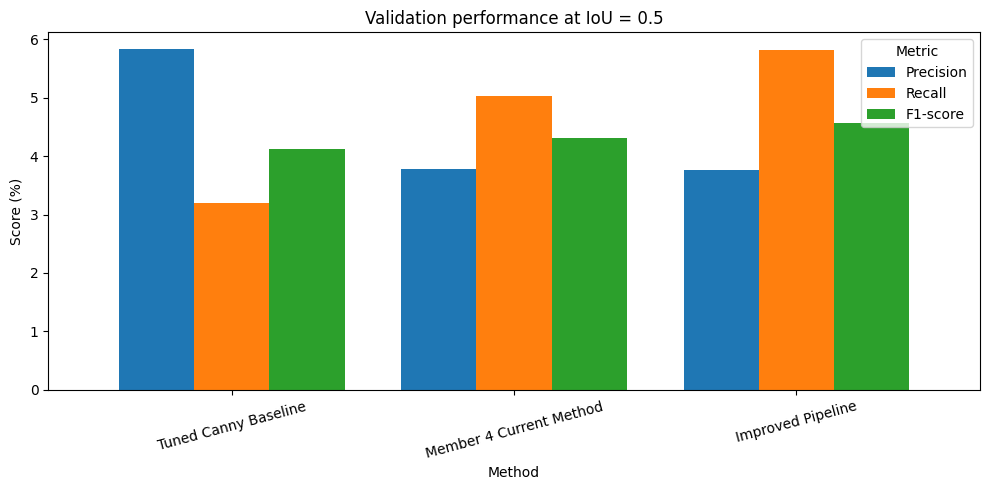

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

M5_VAL_AT_05 = M5_VALIDATION_IOU_RESULTS[
    np.isclose(M5_VALIDATION_IOU_RESULTS["IoU_threshold"], 0.5)
].copy()

M5_METRICS_PERCENT = (
    M5_VAL_AT_05
    .set_index("method")[["precision", "recall", "F1_score"]]
    .mul(100)
)

ax = M5_METRICS_PERCENT.plot(
    kind="bar",
    figsize=(10, 5),
    width=0.8
)

ax.set_title("Validation performance at IoU = 0.5")
ax.set_xlabel("Method")
ax.set_ylabel("Score (%)")
ax.tick_params(axis="x", rotation=15)
ax.legend(
    ["Precision", "Recall", "F1-score"],
    title="Metric"
)
plt.tight_layout()
plt.show()

###Validation TP, FP, and FN Comparison at IoU = 0.5

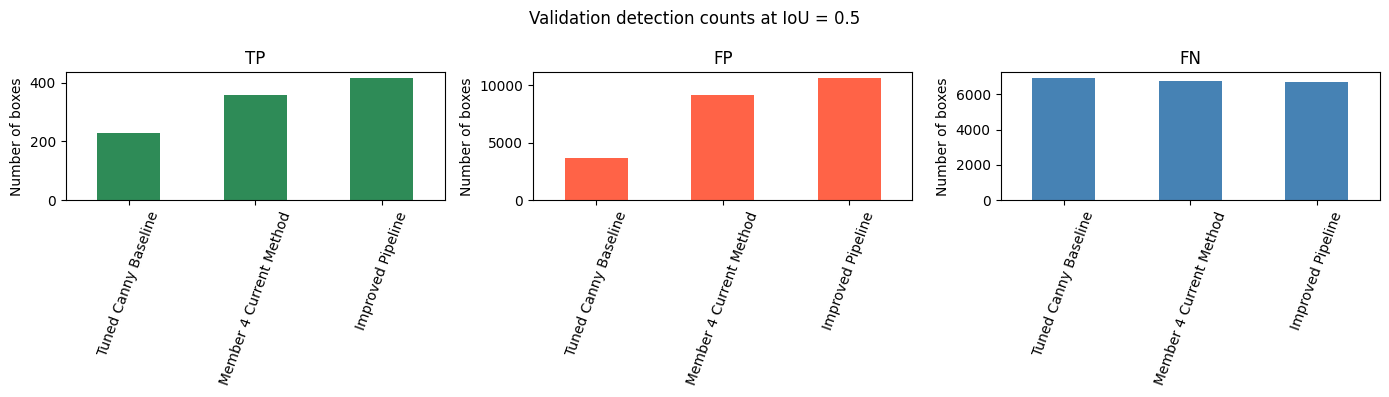

In [ ]:
M5_COUNTS = (
    M5_VAL_AT_05
    .set_index("method")[["TP", "FP", "FN"]]
)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, metric in zip(axes, ["TP", "FP", "FN"]):
    M5_COUNTS[metric].plot(
        kind="bar",
        ax=ax,
        color={"TP": "seagreen", "FP": "tomato", "FN": "steelblue"}[metric]
    )
    ax.set_title(metric)
    ax.set_xlabel("")
    ax.set_ylabel("Number of boxes")
    ax.tick_params(axis="x", rotation=70)

fig.suptitle("Validation detection counts at IoU = 0.5")
plt.tight_layout()
plt.show()